Для выполнения второго домашнего задания был выбран следующий датасет: [https://github.com/md-121/yellow-sticky-traps-dataset](https://github.com/md-121/yellow-sticky-traps-dataset)

# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:**

Работа выполняется локально на NVIDIA RTX 3060 с 12 ГБ памяти. Используются PyTorch 2.14.1 с CUDA 13.0, ultralytics 8.4.40 и модель yolo26n.pt.

Датасет Yellow Sticky Traps содержит фотографии клеевых ловушек с тремя классами насекомых. Источник: [Yellow Sticky Traps](https://github.com/md-121/yellow-sticky-traps-dataset), лицензия CC0-1.0. Выбраны бонусы 6.2, 6.3, 6.4 и 6.5, бонус 6.1 не выполнялся.

Источники: условия задания, [документация Ultralytics](https://docs.ultralytics.com/), [конфигурация YOLO26 используемой версии](https://github.com/ultralytics/ultralytics/blob/v8.4.40/ultralytics/cfg/models/26/yolo26.yaml) и описание датасета. Реализация и разбор результатов подготовлены с помощью Codex.

Выполнен полный прогон с FAST_MODE = False: 198 изображений train, разрешение 640, до 60 эпох. Основное обучение завершилось на 55-й эпохе по early stopping, лучшие веса получены на 40-й. Результаты второго ДЗ сохраняются в artifacts/hw2, отдельно от первого ДЗ.


In [1]:
# При необходимости в текущем kernel: %pip install -r requirements_cv.txt
import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import urllib.request
import xml.etree.ElementTree as ET
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import ultralytics
from matplotlib.patches import Rectangle
from PIL import Image, ImageEnhance
from scipy import ndimage
from torchvision.ops import box_iou
from ultralytics import RTDETR, YOLO

assert ultralytics.__version__ == "8.4.40", "Установи ultralytics==8.4.40 из requirements_cv.txt"

plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 12

try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats

    set_matplotlib_formats("jpeg")
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f"ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}")

ultralytics 8.4.40, torch 2.14.1+cu130, device: NVIDIA GeForce RTX 3060


In [2]:
FAST_MODE = False  # True - отладка, False - финальный прогон
BONUS_TASKS = {"6.2", "6.3", "6.4", "6.5"}
assert {"6.1", "6.2", "6.3", "6.4", "6.5"} >= BONUS_TASKS

SEED = 0
DATA_ROOT = Path("data")
RUNS = Path("runs_hw2")
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 60
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64
WORKERS = 0 if os.name == "nt" else 2
RUN_TIMES = {}
BONUS_RESULTS = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle="-", title=None):
    if image is not None:
        if isinstance(image, Image.Image):
            width, height = image.size
            scale = min(1, 1400 / max(width, height))
            preview = image.resize((max(1, round(width * scale)), max(1, round(height * scale))))
            ax.imshow(preview, extent=(0, width, height, 0))
        else:
            ax.imshow(image)

    for k, (box, label) in enumerate(
        zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1), strict=False)
    ):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(
            Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=c,
                linewidth=1.5,
                linestyle=linestyle,
            )
        )
        short_names = {
            "Macrolophus pygmaeus": "MR",
            "Nesidiocoris tenuis": "NC",
            "Trialeurodes vaporariorum": "WF",
        }
        name = names[int(label)]
        text = short_names.get(name, name) + ("" if scores is None else f" {scores[k]:.3g}")

        if text:
            label_y = y1 if scores is not None else y2
            label_offset = 2 if scores is not None else -2
            caption = ax.annotate(
                text,
                xy=(x1, label_y),
                xytext=(0, label_offset),
                textcoords="offset points",
                va="bottom" if scores is not None else "top",
                color="white",
                fontsize=8,
                clip_on=True,
                annotation_clip=True,
                bbox=dict(facecolor=c, alpha=0.8, pad=1, edgecolor="none"),
            )
            caption.set_in_layout(False)

    ax.set_axis_off()

    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с
    # монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки,
    # но не равны
    aps = []

    for c in range(n_classes):
        hits, n_gt = [], 0

        for p, g in zip(preds, gts, strict=False):
            gb = torch.as_tensor(
                np.asarray(g["boxes"])[np.asarray(g["labels"]) == c], dtype=torch.float32
            ).reshape(-1, 4)
            keep = np.asarray(p["labels"]) == c
            pb = torch.as_tensor(np.asarray(p["boxes"])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p["scores"])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)

            for i in np.argsort(-ps, kind="stable"):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]

                if hit:
                    used[j] = True

                hits.append((ps[i], hit))

        if n_gt == 0:
            aps.append(float("nan"))
            continue

        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))

    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []

    for i in range(0, len(recs), batch):
        paths = [str(r["image"]) for r in recs[i : i + batch]]

        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(
                dict(
                    boxes=b.xyxy.numpy(),
                    scores=b.conf.numpy(),
                    labels=b.cls.numpy().astype(np.int64),
                )
            )

    return out


def box_window(box, width, height, min_side=600, max_side=1400):
    center = (box[:2] + box[2:]) / 2
    side = np.clip(np.max(box[2:] - box[:2]) * 2, min_side, max_side)
    lo = np.maximum(0, center - side / 2)
    hi = np.minimum([width, height], center + side / 2)

    return np.r_[lo, hi]


def visible_boxes(boxes, window):
    boxes = np.asarray(boxes).reshape(-1, 4)

    return np.flatnonzero(
        (np.minimum(boxes[:, 2:], window[2:]) > np.maximum(boxes[:, :2], window[:2])).all(axis=1)
    )


def set_window(ax, window):
    ax.set_xlim(window[0], window[2])
    ax.set_ylim(window[3], window[1])


def draw_crop(ax, image, window):
    x1, y1 = np.floor(window[:2]).astype(int)
    x2, y2 = np.ceil(window[2:]).astype(int)

    with image.crop((x1, y1, x2, y2)) as crop:
        ax.imshow(crop, extent=(x1, x2, y2, y1))


def print_metric_summary(title, summary):
    print(title)
    print(f"{'class':<9} {'P':>9} {'R':>9} {'mAP50':>9} {'mAP50-95':>11}")
    rows = [("all", summary)]
    short_names = {
        "Macrolophus pygmaeus": "MR",
        "Nesidiocoris tenuis": "NC",
        "Trialeurodes vaporariorum": "WF",
    }

    for name, row in summary.get("per_class", {}).items():
        rows.append((short_names.get(name, name), row))

    for name, row in rows:
        print(
            f"{name:<9} {row['precision']:>9.4f} {row['recall']:>9.4f} "
            f"{row['map50']:>9.4f} {row['map50_95']:>11.4f}"
        )

    print()

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = "yolo26n.pt"
model_coco = YOLO(WEIGHTS)
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)


def file_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


def synchronize():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elif DEVICE == "mps":
        torch.mps.synchronize()


def latency_ms(model, image, repeats=20, **kwargs):
    # Batch 1, полный predict: preprocessing + модель + postprocessing.
    args = dict(imgsz=IMGSZ, device=DEVICE, conf=0.001, verbose=False, rect=False)
    args.update(kwargs)

    for _ in range(5):
        model.predict(image, **args)

    synchronize()
    times = []

    for _ in range(repeats):
        synchronize()
        start = time.perf_counter()
        model.predict(image, **args)
        synchronize()
        times.append((time.perf_counter() - start) * 1000)

    return dict(mean=float(np.mean(times)), std=float(np.std(times)), repeats=repeats)


MODEL_INFO = dict(
    ultralytics=ultralytics.__version__,
    weights=weights_path.name,
    sha256=file_sha256(weights_path),
    size_mb=weights_path.stat().st_size / 1e6,
    params=sum(p.numel() for p in model_coco.model.parameters()),
    n_classes_coco=len(model_coco.names),
)
dummy_image = np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8)
MODEL_INFO["latency_ms"] = latency_ms(model_coco, dummy_image)["mean"]
MODEL_INFO["latency_scope"] = "predict, batch=1, FP32, rect=False, 5 warmup + 20 repeats"

In [5]:
assert "MODEL_INFO" in globals(), "сначала заполните MODEL_INFO в ячейке выше"
assert set(MODEL_INFO) >= {
    "ultralytics",
    "weights",
    "sha256",
    "size_mb",
    "params",
    "n_classes_coco",
    "latency_ms",
}
assert len(MODEL_INFO["sha256"]) == 64 and MODEL_INFO["params"] > 0 and MODEL_INFO["latency_ms"] > 0

MODEL_INFO

{'ultralytics': '8.4.40',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.544453,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 19.10140999993928,
 'latency_scope': 'predict, batch=1, FP32, rect=False, 5 warmup + 20 repeats'}

**Ответ:**

Для работы была выбрана YOLO26n, т.к. датасет небольшой, а кроме основного обучения нужно выполнить абляцию и сравнение с RT-DETR. Небольшая модель позволяет провести эти эксперименты локально на RTX 3060.

По [таблице Ultralytics](https://docs.ultralytics.com/models/yolo26/#performance-metrics), YOLO26n имеет 2,4 млн параметров после слияния слоев и удаления неиспользуемой ветки, а YOLO26s - 9,5 млн. Для COCO mAP50-95 составляет 40,9 и 48,6 соответственно, для ветки end-to-end - 40,1 и 47,8. Задержка на T4 TensorRT составляет 1,7 и 2,5 мс. То есть соседний размер дает более высокое качество, но требует больше вычислений.

В загруженной модели до первого predict было 2 572 280 параметров, т.к. она содержит обе ветки головы и отдельные BatchNorm. Замер полного predict на RTX 3060 дал 24,99 мс при размере 640. Его нельзя напрямую сравнивать с TensorRT из таблицы, т.к. отличаются устройство, разрешение и состав измеряемых операций.

Код и открытые веса Ultralytics предоставляются по AGPL-3.0. При распространении производной работы нужно соблюдать условия этой лицензии, сохранять уведомления и предоставлять соответствующий исходный код; для измененной программы предусмотрено предоставление исходников пользователям, взаимодействующим с ней по сети. Для закрытого использования Ultralytics предлагает отдельную коммерческую лицензию. Источник: [лицензирование Ultralytics](https://www.ultralytics.com/license).


## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    layers = det_model.model
    n_backbone = len(det_model.yaml["backbone"])

    return dict(
        backbone=sum(p.numel() for layer in layers[:n_backbone] for p in layer.parameters()),
        neck=sum(p.numel() for layer in layers[n_backbone:-1] for p in layer.parameters()),
        head=sum(p.numel() for p in layers[-1].parameters()),
    )


def head_inputs_and_output(det_model, imgsz=640):
    feature_shapes = []

    def save_shapes(module, inputs):
        feature_shapes.extend(tuple(x.shape) for x in inputs[0])

    handle = det_model.model[-1].register_forward_pre_hook(save_shapes)
    training = {module: module.training for module in det_model.modules()}
    parameter = next(det_model.parameters())

    try:
        det_model.eval()
        x = torch.zeros(1, 3, imgsz, imgsz, device=parameter.device, dtype=parameter.dtype)

        with torch.no_grad():
            output = det_model(x)
    finally:
        handle.remove()

        for module, state in training.items():
            module.training = state

    return feature_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)

    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]

    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}

    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model  # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {"backbone", "neck", "head"}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks["head"] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], (
    feat_shapes
)  # страйды 8, 16, 32

print({k: f"{v:,} ({v / total:.0%})" for k, v in blocks.items()}, f"total {total:,}")
print("на входе Detect:", feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print("выход модели:", shapes(out))
print("число точек на картах:", sum(s[-2] * s[-1] for s in feat_shapes))

выход модели: [(1, 300, 6), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]
число точек на картах: 8400


**Ответ:**

Backbone последовательно уменьшает пространственное разрешение и выделяет признаки изображения. В используемой модели он содержит Conv, блоки C3k2, SPPF для расширения контекста и C2PSA с механизмом внимания. Neck объединяет глубокие признаки с более детальными картами через увеличение разрешения, конкатенации и последующее уменьшение разрешения.

В Detect поступают карты размеров 80 на 80, 40 на 40 и 20 на 20 при входе 640 на 640. Их шаги относительно изображения равны 8, 16 и 32, а общее число позиций составляет 6400 + 1600 + 400 = 8400. В каждой позиции голова предсказывает координаты бокса и оценки классов. Отдельного заранее заданного набора боксов с фиксированными размерами и пропорциями нет, поэтому модель называют anchor-free.

Ветка one2many допускает несколько положительных предсказаний на один объект и при обычном инференсе использует NMS. Ветка one2one обучается с назначением одного положительного предсказания на объект, поэтому в режиме end-to-end можно обойтись без NMS. В текущей версии этот режим включен по умолчанию, итоговый выход имеет форму 1 на 300 на 6: координаты, score и индекс класса. При этом 300 - верхний предел числа предсказаний.

В backbone находится 1 365 472 параметра, в neck - 897 152, в head - 309 656. Это примерно 53,08, 34,88 и 12,04 процента от общего числа параметров.


---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
DATASET_NAME = "Yellow Sticky Traps (Deserno and Briassouli, 2021)"
DATASET_URL = "https://github.com/md-121/yellow-sticky-traps-dataset"
DATASET_LICENSE = "CC0-1.0"
DATASET_ROOT = Path("yellow-sticky-traps-dataset-main")
CLASSES = ["Macrolophus pygmaeus", "Nesidiocoris tenuis", "Trialeurodes vaporariorum"]
CLASS_IDS = {"MR": 0, "NC": 1, "WF": 2}

if not DATASET_ROOT.exists():
    DATA_ROOT.mkdir(exist_ok=True)
    archive = DATA_ROOT / "yellow-sticky-traps-dataset-main.zip"
    url = "https://github.com/md-121/yellow-sticky-traps-dataset/archive/refs/heads/main.zip"

    if not archive.exists():
        urllib.request.urlretrieve(url, archive)

    with zipfile.ZipFile(archive) as z:
        # Архив распаковывается в каталог датасета рядом с notebook.
        root = Path.cwd().resolve()

        for member in z.infolist():
            target = (root / member.filename).resolve()

            if not target.is_relative_to(root / DATASET_ROOT):
                raise ValueError(f"Неожиданный путь в архиве: {member.filename}")

        z.extractall(root)

ANNOTATION_CHECKS = dict(
    total=0,
    non_finite=0,
    non_positive=0,
    out_of_bounds=0,
    clipped=0,
    removed=0,
)
all_records = []

for xml_path in sorted((DATASET_ROOT / "annotations").glob("*.xml")):
    annotation = ET.parse(xml_path).getroot()
    image_path = DATASET_ROOT / "images" / f"{xml_path.stem}.jpg"

    with Image.open(image_path) as image:
        width, height = image.size

    assert (width, height) == (
        int(annotation.findtext("size/width")),
        int(annotation.findtext("size/height")),
    )

    boxes, labels = [], []

    for obj in annotation.findall("object"):
        box = np.array(
            [float(obj.findtext(f"bndbox/{key}")) for key in ("xmin", "ymin", "xmax", "ymax")],
            dtype=float,
        )
        ANNOTATION_CHECKS["total"] += 1

        if not np.isfinite(box).all():
            ANNOTATION_CHECKS["non_finite"] += 1
            ANNOTATION_CHECKS["removed"] += 1
            continue

        limits = np.array([width, height, width, height])

        if ((box < 0) | (box > limits)).any():
            ANNOTATION_CHECKS["out_of_bounds"] += 1

        if (box[2:] <= box[:2]).any():
            ANNOTATION_CHECKS["non_positive"] += 1
            ANNOTATION_CHECKS["removed"] += 1
            continue

        # LabelImg: используем координаты нарисованных границ, без сдвига на 1 px.
        clipped_box = np.clip(box, 0, limits)

        if (clipped_box[2:] <= clipped_box[:2]).any():
            ANNOTATION_CHECKS["removed"] += 1
            continue

        if not np.array_equal(box, clipped_box):
            ANNOTATION_CHECKS["clipped"] += 1

        boxes.append(clipped_box)
        labels.append(CLASS_IDS[obj.findtext("name")])

    all_records.append(
        dict(
            image=image_path,
            width=width,
            height=height,
            boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4),
            labels=np.array(labels, dtype=np.int64),
        )
    )

assert len(all_records) == 284

print("Проверка исходной разметки:")
print("Всего боксов:", ANNOTATION_CHECKS["total"])
print("Нечисловые координаты:", ANNOTATION_CHECKS["non_finite"])
print("Нулевая или отрицательная площадь:", ANNOTATION_CHECKS["non_positive"])
print("Выход за границы изображения:", ANNOTATION_CHECKS["out_of_bounds"])
print("Обрезано до границ:", ANNOTATION_CHECKS["clipped"])
print("Удалено:", ANNOTATION_CHECKS["removed"])
print()

# Одинаковые файлы не должны попадать в разные сплиты.
hashes = [file_sha256(r["image"]) for r in all_records]
assert len(set(hashes)) == len(hashes), "Обнаружены дубликаты: сначала нужно объединить их в группы"

order = np.random.default_rng(SEED).permutation(len(all_records))
n_train, n_val = int(0.7 * len(order)), int(0.15 * len(order))
indices = dict(
    train=order[:n_train], val=order[n_train : n_train + n_val], test=order[n_train + n_val :]
)
records = {split: [all_records[i] for i in idx] for split, idx in indices.items()}

for split, recs in records.items():
    counts = np.bincount(np.concatenate([r["labels"] for r in recs]), minlength=len(CLASSES))
    assert (counts > 0).all(), (split, counts)

    print(split, len(recs), "images;", dict(zip(CLASSES, counts.tolist(), strict=False)))

Проверка исходной разметки:
Всего боксов: 8114
Нечисловые координаты: 0
Нулевая или отрицательная площадь: 0
Выход за границы изображения: 0
Обрезано до границ: 0
Удалено: 0

train 198 images; {'Macrolophus pygmaeus': 1207, 'Nesidiocoris tenuis': 485, 'Trialeurodes vaporariorum': 4025}
val 42 images; {'Macrolophus pygmaeus': 253, 'Nesidiocoris tenuis': 79, 'Trialeurodes vaporariorum': 893}
test 44 images; {'Macrolophus pygmaeus': 159, 'Nesidiocoris tenuis': 124, 'Trialeurodes vaporariorum': 889}


In [10]:
assert all(n in globals() for n in ("records", "CLASSES", "DATASET_NAME")), (
    "сначала заполните records, CLASSES, DATASET_NAME"
)
assert {"train", "val"} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)

for split, recs in records.items():  # noqa: B007
    for r in recs:
        assert Path(r["image"]).exists() and r["boxes"].shape == (len(r["labels"]), 4), r["image"]
        assert (r["boxes"][:, 2] > r["boxes"][:, 0]).all() and (
            r["boxes"][:, 3] > r["boxes"][:, 1]
        ).all(), r["image"]
        assert ((r["labels"] >= 0) & (r["labels"] < len(CLASSES))).all(), r["image"]

{split: len(recs) for split, recs in records.items()}

{'train': 198, 'val': 42, 'test': 44}

Число объектов на изображение:
split    images  objects     mean   median    min    max
train       198     5717    28.87     15.0      1    327
val          42     1225    29.17     20.5      4     86
test         44     1172    26.64     13.5      2    227

Macrolophus pygmaeus median object size after resize: 15.4 px
Nesidiocoris tenuis median object size after resize: 15.7 px
Trialeurodes vaporariorum median object size after resize: 5.8 px


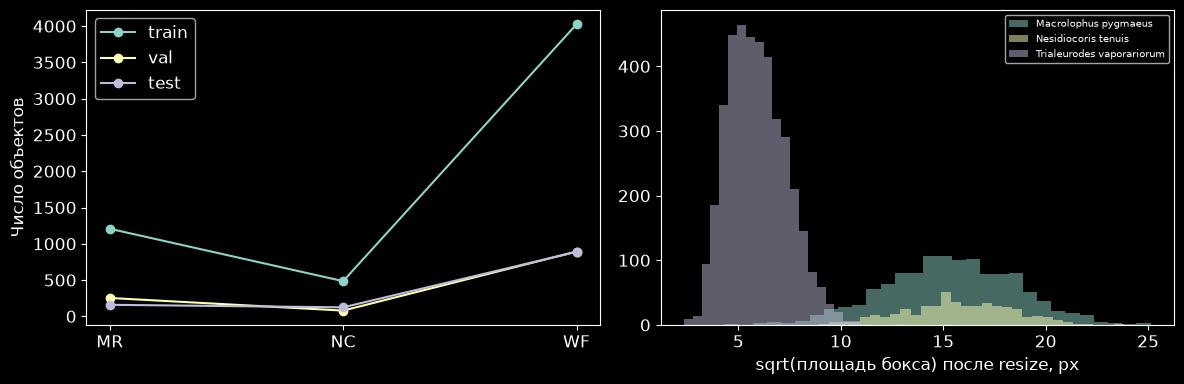

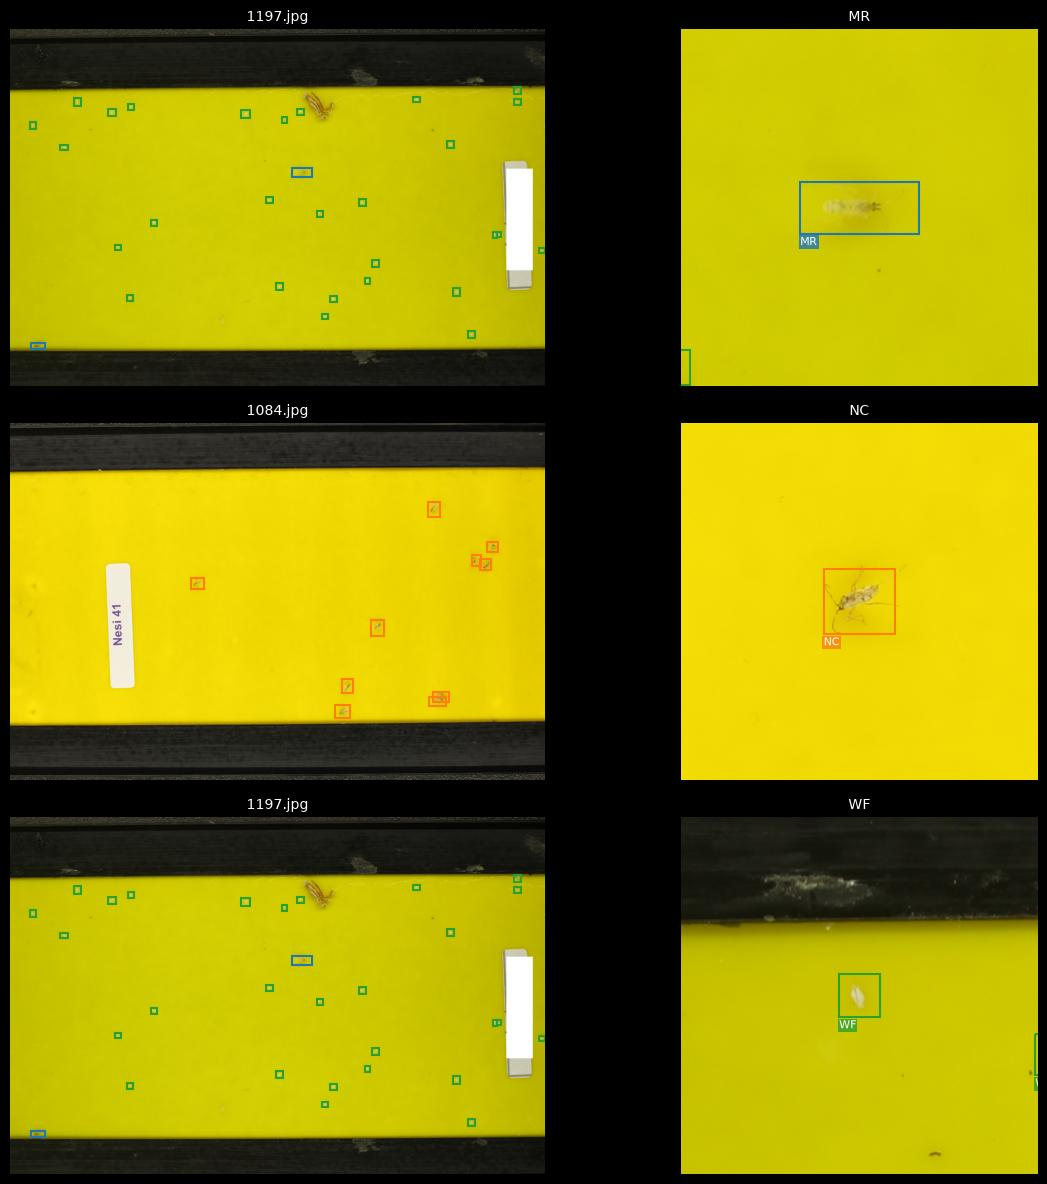

In [11]:
DATASET_STATS = {}

print("Число объектов на изображение:")
print(f"{'split':<7} {'images':>7} {'objects':>8} {'mean':>8} {'median':>8} {'min':>6} {'max':>6}")

for split, recs in records.items():
    object_counts = np.array([len(r["boxes"]) for r in recs], dtype=np.int64)
    stats = dict(
        images=len(recs),
        objects=int(object_counts.sum()),
        mean=float(object_counts.mean()),
        median=float(np.median(object_counts)),
        min=int(object_counts.min()),
        max=int(object_counts.max()),
    )
    DATASET_STATS[split] = stats
    print(
        f"{split:<7} {stats['images']:>7} {stats['objects']:>8} "
        f"{stats['mean']:>8.2f} {stats['median']:>8.1f} "
        f"{stats['min']:>6} {stats['max']:>6}"
    )

print()


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for split, recs in records.items():
    counts = np.bincount(np.concatenate([r["labels"] for r in recs]), minlength=len(CLASSES))
    axes[0].plot(["MR", "NC", "WF"], counts, "o-", label=split)

axes[0].set_ylabel("Число объектов")
axes[0].legend()

for class_id, name in enumerate(CLASSES):
    sizes = []

    for r in records["train"]:
        wh = r["boxes"][r["labels"] == class_id, 2:] - r["boxes"][r["labels"] == class_id, :2]
        sizes.extend(np.sqrt(wh.prod(axis=1)) * IMGSZ / max(r["width"], r["height"]))

    axes[1].hist(sizes, bins=30, alpha=0.5, label=name)
    print(name, "median object size after resize:", round(float(np.median(sizes)), 1), "px")

axes[1].set_xlabel("sqrt(площадь бокса) после resize, px")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()


# Общий вид без подписей и увеличенный фрагмент для каждого класса.
fig, axes = plt.subplots(3, 2, figsize=(13, 12))

for class_id in range(len(CLASSES)):
    r = next(r for r in records["train"] if class_id in r["labels"])
    focus = int(np.flatnonzero(r["labels"] == class_id)[0])
    window = box_window(r["boxes"][focus], r["width"], r["height"])
    visible = visible_boxes(r["boxes"], window)

    with Image.open(r["image"]) as image:
        draw_boxes(
            axes[class_id, 0], image, r["boxes"], r["labels"], ["", "", ""], title=r["image"].name
        )
        draw_crop(axes[class_id, 1], image, window)
        draw_boxes(
            axes[class_id, 1],
            None,
            r["boxes"][visible],
            r["labels"][visible],
            CLASSES,
            title=["MR", "NC", "WF"][class_id],
        )

    set_window(axes[class_id, 1], window)

plt.tight_layout()
plt.show()

**Ответ:**

Был выбран Yellow Sticky Traps, т.к. он содержит небольшие объекты и похожие классы, которых нет в COCO. Это позволяет проверить перенос предобученных признаков на другой домен и влияние разрешения на детекцию мелких насекомых. В репозитории указана лицензия CC0-1.0.

Всего в датасете 284 фотографии и 8114 объектов. Для Macrolophus pygmaeus имеется 1619 боксов, для Nesidiocoris tenuis - 688, для Trialeurodes vaporariorum (в дальнейшем также будем называть её белокрылкой) - 5807. То есть последний класс заметно преобладает, а Nesidiocoris tenuis представлен слабее остальных.

Изображения разделены с SEED = 0 на 198 train, 42 val и 44 test. Разметка хранится в VOC XML, изображения имеют размер 5184 на 3456. При уменьшении до 640 медианный линейный размер объекта составляет около 15,4, 15,7 и 5,8 пикселя соответственно. Поэтому сложно ожидать хорошую локализацию последнего класса.

В среднем на изображении находится 28,87 объекта в train, 29,17 в val и 26,64 в test. Медианы равны 15, 20,5 и 13,5 соответственно, максимумы - 327, 86 и 227, то есть встречаются значительно более плотные сцены.

Нечисловых координат, боксов с нулевой или отрицательной площадью и выходов за границы изображения не обнаружено. Обрезать или удалять боксы на этом датасете не потребовалось.


## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    labels = np.asarray(labels, dtype=np.int64).reshape(-1)

    if width <= 0 or height <= 0 or len(boxes) != len(labels):
        raise ValueError("Неверные размеры изображения или разметки")

    if not np.isfinite(boxes).all() or (labels < 0).any():
        raise ValueError("Неверные координаты или классы")

    if (boxes[:, :2] < 0).any() or (boxes[:, 2:] > [width, height]).any():
        raise ValueError("Бокс выходит за границы изображения")

    wh = boxes[:, 2:] - boxes[:, :2]

    if (wh <= 0).any():
        raise ValueError("Площадь бокса должна быть положительной")

    centers = (boxes[:, :2] + boxes[:, 2:]) / 2
    normalized = np.concatenate([centers, wh], axis=1) / [width, height, width, height]

    return "".join(
        f"{int(label)} " + " ".join(f"{x:.6f}" for x in box) + "\n"
        for label, box in zip(labels, normalized, strict=False)
    )


def from_yolo(text, width, height):
    boxes, labels = [], []

    if width <= 0 or height <= 0:
        raise ValueError("Размеры изображения должны быть положительными")

    for line in text.splitlines():
        if not line.strip():
            continue

        fields = line.split()

        if len(fields) != 5:
            raise ValueError(f"Ожидались class cx cy w h: {line}")

        label = int(fields[0])
        cx, cy, w, h = np.array(fields[1:], dtype=float)
        values = np.array([cx, cy, w, h])

        if (
            label < 0
            or not np.isfinite(values).all()
            or (values < 0).any()
            or (values > 1).any()
            or min(w, h) <= 0
        ):
            raise ValueError(f"Некорректная YOLO-разметка: {line}")

        boxes.append(
            [
                (cx - w / 2) * width,
                (cy - h / 2) * height,
                (cx + w / 2) * width,
                (cy + h / 2) * height,
            ]
        )
        labels.append(label)

    return np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(labels, dtype=np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ["2", "0.300000", "0.450000", "0.500000", "0.500000"], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ""

b, l = from_yolo("", 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)

b, l = from_yolo("1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n", 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [
    1,
    0,
], (b, l)

rng = np.random.default_rng(0)

for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate(
        [xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1
    )
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()

print("to_yolo / from_yolo: ok")

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / "hw2_sticky_yolo"


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    image_dir = YOLO_ROOT / "images" / split
    label_dir = YOLO_ROOT / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for r in recs:
        destination = image_dir / r["image"].name

        # Hard link не занимает место второй копией исходной фотографии.
        try:
            os.link(r["image"], destination)
        except OSError:
            shutil.copy2(r["image"], destination)

        text = to_yolo(r["boxes"], r["labels"], r["width"], r["height"])
        (label_dir / f"{r['image'].stem}.txt").write_text(text, encoding="utf-8")


order = np.random.default_rng(SEED).permutation(len(records["train"]))
train_recs = [records["train"][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records["train"]
shutil.rmtree(
    YOLO_ROOT, ignore_errors=True
)  # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {"train": train_recs, **{s: r for s, r in records.items() if s != "train"}}

for split, recs in splits.items():
    export_split(recs, split)

DATA_YAML = YOLO_ROOT / "data.yaml"
DATA_YAML.write_text(
    f"path: {YOLO_ROOT.resolve().as_posix()}\n"
    + "".join(f"{s}: images/{s}\n" for s in splits)
    + "names:\n"
    + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASSES))
)

for split, recs in splits.items():
    assert len(list((YOLO_ROOT / "labels" / split).glob("*.txt"))) == len(recs), split

FINAL_SPLIT = (
    "test" if "test" in records else "val"
)  # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: D:/Deep-Learning-homeworks/data/hw2_sticky_yolo
train: images/train
val: images/val
test: images/test
names:
  0: Macrolophus pygmaeus
  1: Nesidiocoris tenuis
  2: Trialeurodes vaporariorum


max roundtrip error: 0.00390625 px


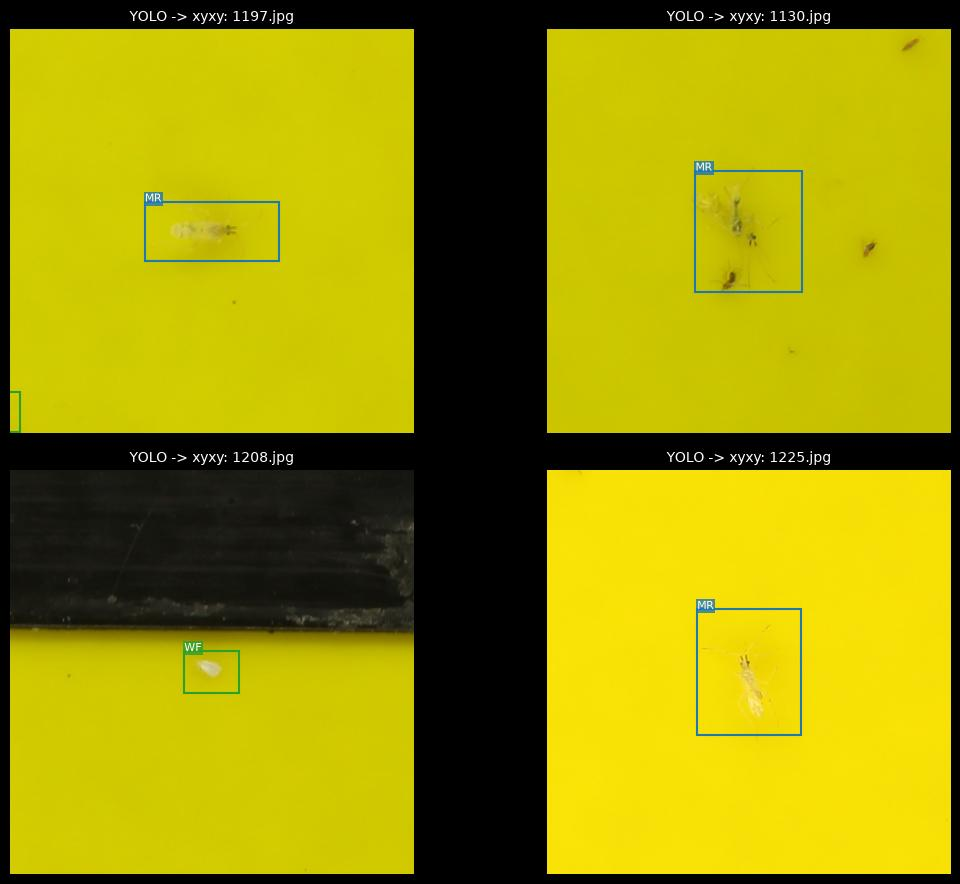

In [15]:
max_roundtrip_error = 0.0

for split, recs in splits.items():
    for r in recs:
        text = (YOLO_ROOT / "labels" / split / f"{r['image'].stem}.txt").read_text(encoding="utf-8")
        boxes, labels = from_yolo(text, r["width"], r["height"])
        assert np.array_equal(labels, r["labels"])

        error = float(np.max(np.abs(boxes - r["boxes"]))) if len(boxes) else 0.0
        assert error <= 1e-5 * max(r["width"], r["height"]) + 1e-3

        max_roundtrip_error = max(max_roundtrip_error, error)

print("max roundtrip error:", max_roundtrip_error, "px")


fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, r in zip(axes.flat, train_recs[:4], strict=False):
    text = (YOLO_ROOT / "labels" / "train" / f"{r['image'].stem}.txt").read_text(encoding="utf-8")
    boxes, labels = from_yolo(text, r["width"], r["height"])
    focus = int(np.argmax(np.prod(boxes[:, 2:] - boxes[:, :2], axis=1)))
    window = box_window(boxes[focus], r["width"], r["height"])
    visible = visible_boxes(boxes, window)

    with Image.open(r["image"]) as image:
        draw_crop(ax, image, window)
        draw_boxes(
            ax,
            None,
            boxes[visible],
            labels[visible],
            CLASSES,
            title=f"YOLO -> xyxy: {r['image'].name}",
        )

    set_window(ax, window)

plt.tight_layout()
plt.show()

**Ответ:**

Тест туда-обратно проверяет, что после записи нормированных координат и обратного чтения сохраняются классы и положения боксов с учетом округления. На экспортированных данных максимальная ошибка составила 0,00390625 пикселя, что значительно меньше размера объекта.

При этом, если обе функции одинаково ошибаются в трактовке координат, например согласованно меняют оси, обратное преобразование может восстановить исходные числа. Также он не проверяет корректность разметки или правильное сопоставление классов. В том числе, не проверяется корректность сопоставления файлов разметки и фотографий.

Поэтому дополнительно показаны увеличенные фрагменты изображений с боксами, прочитанными из YOLO-файлов. На них можно проверить корректность разметки.


---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

COCO mAP50: 0.0
Исходные предсказания COCO: Counter({'bird': 4000, 'kite': 717, 'airplane': 407, 'boat': 365, 'banana': 328, 'person': 246, 'sports ball': 166, 'apple': 83, 'bench': 77, 'tv': 58, 'bowl': 58, 'dining table': 55, 'train': 54, 'clock': 48, 'surfboard': 45, 'book': 44, 'truck': 42, 'car': 31, 'remote': 29, 'bus': 27, 'orange': 26, 'laptop': 20, 'cell phone': 19, 'cake': 17, 'umbrella': 15, 'sheep': 15, 'knife': 12, 'frisbee': 10, 'toothbrush': 10, 'pizza': 9, 'skateboard': 9, 'oven': 7, 'donut': 7, 'traffic light': 7, 'scissors': 7, 'bottle': 6, 'stop sign': 4, 'cup': 4, 'mouse': 4, 'horse': 4, 'hot dog': 3, 'sandwich': 3, 'microwave': 2, 'suitcase': 2, 'sink': 2, 'baseball bat': 2, 'keyboard': 2, 'potted plant': 2, 'toilet': 1, 'fork': 1, 'skis': 1, 'dog': 1, 'spoon': 1, 'fire hydrant': 1, 'snowboard': 1, 'chair': 1, 'cow': 1})


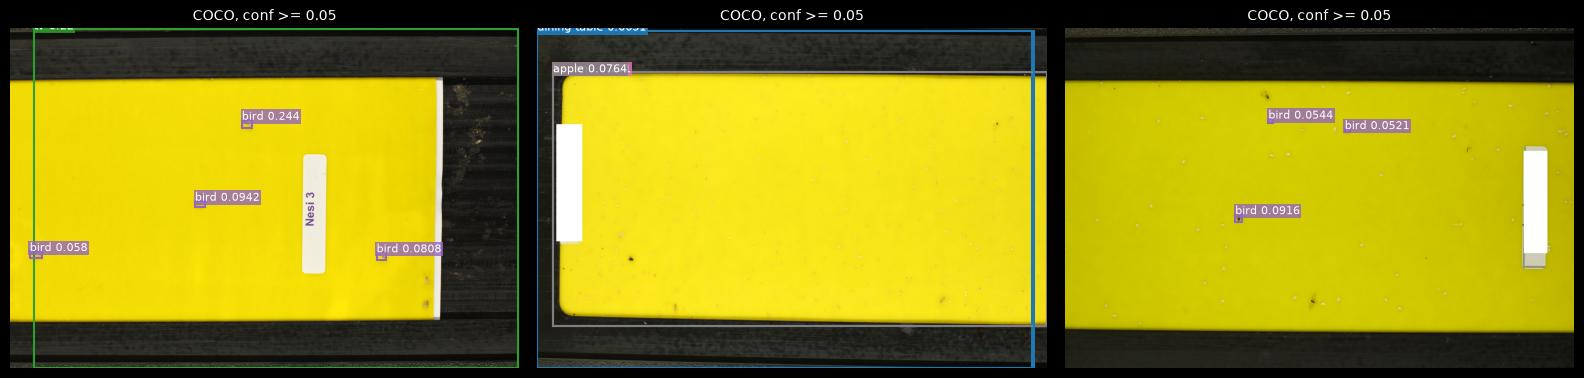

In [16]:
start = time.perf_counter()
coco_preds_raw = predict_records(model_coco, records[FINAL_SPLIT], rect=False)
# В COCO нет ни одного из трёх видов насекомых: отображение классов пустое.
COCO_TO_DATASET = {}
coco_preds = []

for pred in coco_preds_raw:
    keep = np.array([int(label) in COCO_TO_DATASET for label in pred["labels"]], dtype=bool)
    coco_preds.append(
        dict(
            boxes=pred["boxes"][keep],
            scores=pred["scores"][keep],
            labels=np.array(
                [COCO_TO_DATASET[int(c)] for c in pred["labels"][keep]], dtype=np.int64
            ),
        )
    )

coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES["coco_baseline"] = time.perf_counter() - start
print("COCO mAP50:", coco_map50)
print(
    "Исходные предсказания COCO:",
    Counter(model_coco.names[int(c)] for p in coco_preds_raw for c in p["labels"]),
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, r, pred in zip(axes, records[FINAL_SPLIT][:3], coco_preds_raw[:3], strict=False):
    keep = np.flatnonzero(pred["scores"] >= 0.05)

    with Image.open(r["image"]) as image:
        draw_boxes(
            ax,
            image,
            pred["boxes"][keep],
            pred["labels"][keep],
            model_coco.names,
            scores=pred["scores"][keep],
            title="COCO, conf >= 0.05",
        )

plt.tight_layout()
plt.show()

In [17]:
HEURISTIC_MAX_SIDE = 2048


def heuristic_image(image_path):
    with Image.open(image_path) as image:
        original_size = np.array(image.size)
        image = image.convert("RGB")
        image.thumbnail((HEURISTIC_MAX_SIDE, HEURISTIC_MAX_SIDE))
        pixels = np.asarray(image, dtype=np.float32) / 255

    return pixels, original_size / [pixels.shape[1], pixels.shape[0]]


def component_feature(pixels, component, sl):
    rgb = pixels[sl][component].mean(axis=0)
    area = component.sum()

    return np.r_[rgb, np.log1p(area) / 10]


def heuristic_detect(image_path):
    pixels, scale = heuristic_image(image_path)
    # Жёлтый фон имеет низкую синюю компоненту. Насекомые светлые либо тёмные.
    r, g, b = pixels.transpose(2, 0, 1)
    mask = ((b > 0.65 * r) & (b > 0.65 * g)) | ((r < 0.35) & (g < 0.35))
    mask = ndimage.binary_opening(mask)
    components, _ = ndimage.label(mask)
    boxes, labels, scores = [], [], []

    for index, sl in enumerate(ndimage.find_objects(components), start=1):
        if sl is None:
            continue

        component = components[sl] == index
        area = int(component.sum())

        if not HEURISTIC_AREA[0] <= area <= HEURISTIC_AREA[1]:
            continue

        h, w = component.shape

        if max(w / h, h / w) > 6:
            continue

        feature = component_feature(pixels, component, sl)
        distances = np.linalg.norm((HEURISTIC_PROTOTYPES - feature) / HEURISTIC_SCALE, axis=1)
        label = int(distances.argmin())
        boxes.append(
            np.array([sl[1].start, sl[0].start, sl[1].stop, sl[0].stop]) * np.tile(scale, 2)
        )
        labels.append(label)
        scores.append(float(np.exp(-distances[label])))

    return dict(
        boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4),
        labels=np.array(labels, dtype=np.int64),
        scores=np.array(scores, dtype=np.float32),
    )

In [18]:
# Оценки размеров и цветовых прототипов берутся только из доступного train.
features_by_class = [[] for _ in CLASSES]
train_areas = []

for r in train_recs:
    pixels, scale = heuristic_image(r["image"])

    for box, label in zip(r["boxes"], r["labels"], strict=False):
        x1, y1, x2, y2 = box / np.tile(scale, 2)
        x1, y1 = np.floor([x1, y1]).astype(int)
        x2, y2 = np.ceil([x2, y2]).astype(int)
        crop = pixels[y1:y2, x1:x2]

        if not crop.size:
            continue

        red, green, blue = crop.transpose(2, 0, 1)
        mask = ((blue > 0.65 * red) & (blue > 0.65 * green)) | ((red < 0.35) & (green < 0.35))

        if mask.any():
            features_by_class[int(label)].append(
                np.r_[crop[mask].mean(axis=0), np.log1p(mask.sum()) / 10]
            )

        train_areas.append((x2 - x1) * (y2 - y1))

assert all(features_by_class)

HEURISTIC_PROTOTYPES = np.stack([np.median(values, axis=0) for values in features_by_class])
HEURISTIC_SCALE = np.maximum(np.std(np.concatenate(features_by_class), axis=0), 0.05)
HEURISTIC_AREA = (
    max(2, float(np.quantile(train_areas, 0.01)) * 0.1),
    float(np.quantile(train_areas, 0.99)) * 2,
)
print("component area limits:", HEURISTIC_AREA)
print("prototypes:", HEURISTIC_PROTOTYPES)

component area limits: (14.3, 9221.04)
prototypes: [[    0.76373     0.71863     0.51471     0.21383]
 [    0.76941      0.7098     0.51176     0.16094]
 [    0.94456      0.8943     0.67659     0.32581]]


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r["image"]) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES["heuristic"] = time.perf_counter() - start
BASELINE = dict(
    split=FINAL_SPLIT,
    coco_map50=coco_map50,
    heuristic_map50=heuristic_map50,
    heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps, strict=False)),
)
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.0,
 'heuristic_ap50_per_class': {'Macrolophus pygmaeus': 0.0,
  'Nesidiocoris tenuis': 0.0,
  'Trialeurodes vaporariorum': 0.0}}

**Ответ:**

COCO-модель дала mAP50 = 0, т.к. в ее наборе классов нет ни одного из трех видов насекомых. Среди исходных предсказаний были bird, banana и другие классы COCO, но переназначать их на наши виды было бы некорректно. Этот результат показывает несовпадение задач.

Для тривиального бейзлайна использовались пороги по цвету, связные компоненты и прототипы классов по цвету и площади. Размеры компонентов и прототипы оценивались только по train. На test mAP50 эвристики также равен 0 по всем классам, то есть положительного результата нет ни для одного класса.

Предположительно, цветовых порогов недостаточно, т.к. насекомые отличаются размером, освещением и положением на ловушке, а фон содержит рамку, блики и посторонние элементы. Для проверки этой причины нужно отдельно посмотреть маски и сопоставить найденные компоненты с разметкой.


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды,
    # каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(
        data=str(DATA_YAML),
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS.resolve()),
        name=name,
        exist_ok=True,
        verbose=False,
        **args,
    )

    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / "results.csv", newline="") as f:
        rows = list(csv.DictReader(f))

    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    weight_decay=0.0005,
    warmup_epochs=0 if FAST_MODE else 3,
    cos_lr=True,
    patience=15,
    seed=SEED,
    deterministic=True,
    amp=torch.cuda.is_available(),
    val=True,
    plots=True,
    cache=False,
    rect=False,
    degrees=10,
    translate=0.1,
    scale=0.3,
    fliplr=0.5,
    flipud=0.5,
    hsv_h=0.015,
    hsv_s=0.3,
    hsv_v=0.3,
    mosaic=0.5,
    close_mosaic=0 if FAST_MODE else 10,
    mixup=0.0,
)
RUN_TAG = "fast" if FAST_MODE else "full"
model_ft, RUN_TIMES["train"], run_dir = train_yolo(f"finetune_{RUN_TAG}", **TRAIN_ARGS)
print(f"обучение: {RUN_TIMES['train']:.0f} s на {DEVICE_NAME}, каталог {run_dir}")

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
Overriding model.yaml nc=80 with nc=3

YOLO26n summary: 260 layers, 2,504,970 parameters, 2,504,970 gradients, 5.8 GFLOPs

Transferred 606/708 items from pretrained weights
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: checks passed 
optimizer: AdamW(lr=0.001, momentum=0.937) with parameter groups 114 weight(decay=0.0), 126 weight(decay=0.0005), 126 bias(decay=0.0)
Plotting labels to D:\Deep-Learning-homeworks\runs_hw2\finetune_full\labels.jpg... 
Image sizes 640 train, 640 val
Using 0 dataloader workers
Logging results to D:\Deep-Learning-homeworks\runs_hw2\finetune_full
Starting training for 60 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/60      4.12G      3.288      4.257   0.004061        153        640
                 C

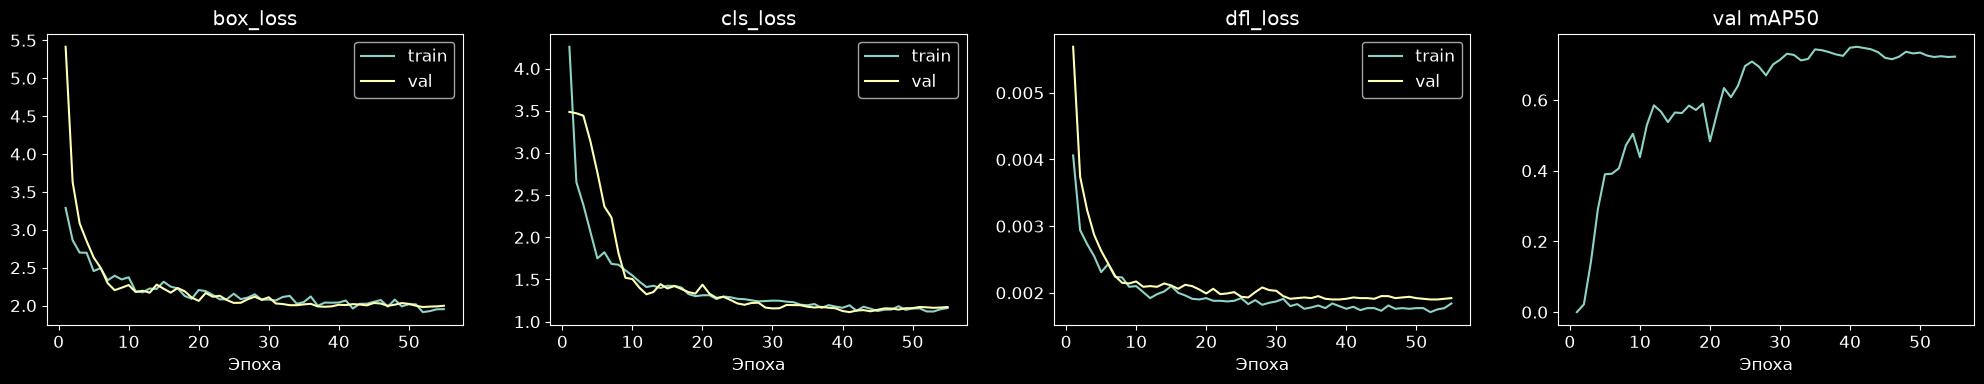

In [22]:
history = read_results(run_dir)
loss_names = sorted(
    {
        name.split("/", 1)[1]
        for name in history
        if name.startswith(("train/", "val/")) and "loss" in name
    }
)
fig, axes = plt.subplots(
    1, len(loss_names) + 1, figsize=(5 * (len(loss_names) + 1), 4), squeeze=False
)

for ax, loss in zip(axes.flat, loss_names, strict=False):
    for split in ("train", "val"):
        key = f"{split}/{loss}"

        if key in history:
            ax.plot(history["epoch"], history[key], label=split)

    ax.set_title(loss)
    ax.set_xlabel("Эпоха")
    ax.legend()

map_key = next(key for key in history if key.startswith("metrics/mAP50("))
axes.flat[-1].plot(history["epoch"], history[map_key])
axes.flat[-1].set_title("val mAP50")
axes.flat[-1].set_xlabel("Эпоха")
plt.tight_layout()
plt.show()

**Ответ:**

Для обучения использовались разрешение 640, batch 16 и AdamW с начальным lr 0,001. Разрешение выбрано из-за мелких объектов, а batch 16 позволяет обучать YOLO26n на RTX 3060 с запасом памяти. Cosine schedule постепенно уменьшает lr, patience 15 завершает обучение при отсутствии улучшения на val.

Повороты и отражения допустимы, т.к. у насекомых на ловушке нет обязательной ориентации. Изменения яркости и цвета моделируют отличия съемки, а mosaic и масштабирование добавляют вариативность. При этом сильное уменьшение изображения затрудняет поиск мелких объектов, поэтому масштабирование ограничено.

Обучение завершилось на 55-й эпохе из заданных 60 и заняло около 1267 секунд, то есть около 21 минуты. Train box loss уменьшился с 3,288 до 1,953, val box loss - с 5,415 до 1,997. Train cls loss уменьшился с 4,257 до 1,162, val cls loss - с 3,486 до 1,174. Обе выборки показывают снижение основных потерь, большого устойчивого разрыва между ними нет.

Лучший результат получен на 40-й эпохе: mAP50-95 на val во время обучения составлял 0,3285, а на последней эпохе - 0,3054. После 40-й эпохи train loss еще немного уменьшался, но качество на val не улучшалось. Это указывает на выход на плато и некоторое ухудшение обобщения к концу обучения, поэтому для оценки использовались лучшие веса. Заданного бюджета хватило для достижения этого плато.


## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / "weights" / "best.pt")
FINETUNED_PARAMS = sum(p.numel() for p in best.model.parameters())


def val_metrics(model, split, name, **kw):
    args = dict(
        data=str(DATA_YAML),
        split=split,
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS.resolve()),
        name=name,
        exist_ok=True,
        verbose=False,
        conf=0.001,
        iou=0.7,
        rect=False,
        plots=True,
        half=False,
    )
    args.update(kw)

    return model.val(**args)


def metric_summary(metrics):
    per_class = {name: dict(precision=0.0, recall=0.0, map50=0.0, map50_95=0.0) for name in CLASSES}

    for index, class_id in enumerate(metrics.box.ap_class_index):
        p, r, ap50, ap = metrics.box.class_result(index)
        per_class[CLASSES[int(class_id)]] = dict(
            precision=float(p), recall=float(r), map50=float(ap50), map50_95=float(ap)
        )

    return dict(
        map50=float(metrics.box.map50),
        map50_95=float(metrics.box.map),
        precision=float(metrics.box.mp),
        recall=float(metrics.box.mr),
        per_class=per_class,
    )

Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
YOLO26n summary (fused): 122 layers, 2,375,421 parameters, 0 gradients, 5.2 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         42       1225      0.714      0.707      0.749      0.326
Speed: 1.7ms preprocess, 14.7ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to D:\Deep-Learning-homeworks\runs_hw2\final_val_full
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         44       1172      0.711      0.726      0.747      0.324
Speed: 1.7ms preprocess, 13.1ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to D:\Deep-Learning-homeworks\runs_hw2\final_test_full
val
class             P         R     mAP50    mAP50-95
all       

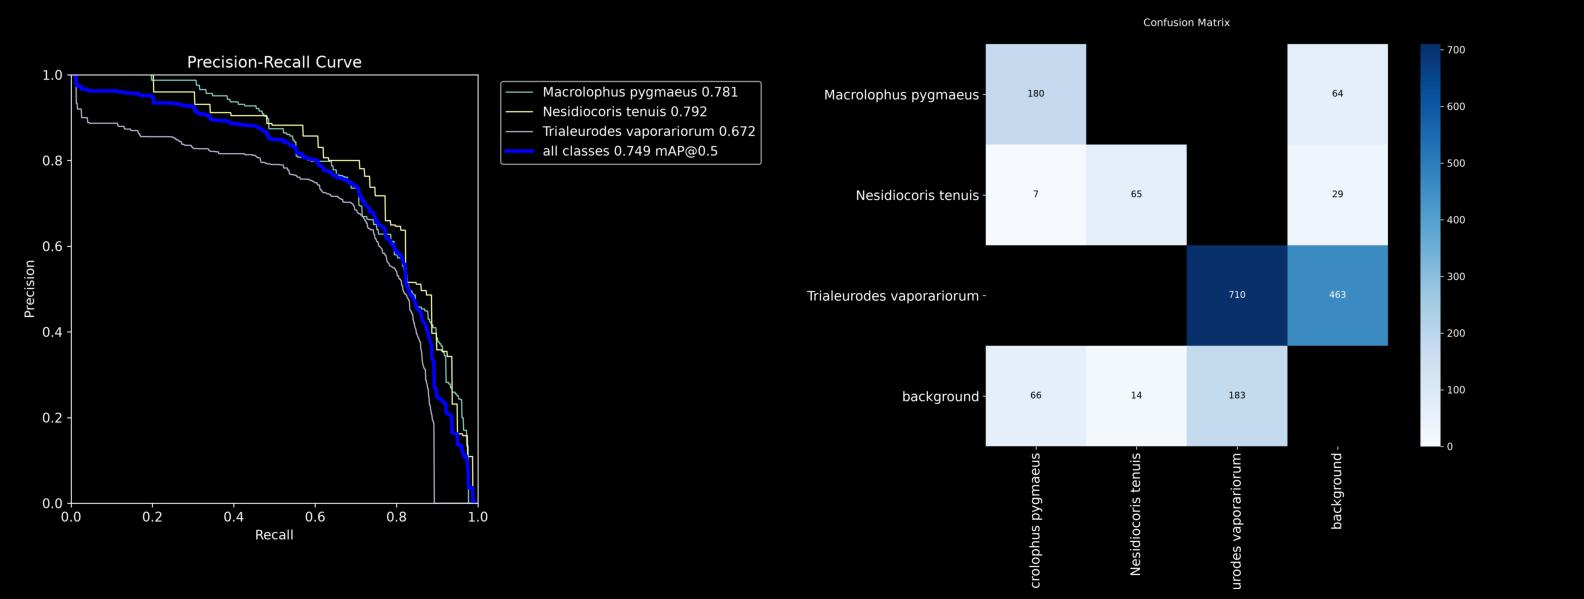

In [24]:
start = time.perf_counter()
evaluations = {
    split: val_metrics(best, split, f"final_{split}_{RUN_TAG}")
    for split in ("val", "test")
    if split in records
}
FINAL_BY_SPLIT = {split: metric_summary(value) for split, value in evaluations.items()}
FINAL = dict(split=FINAL_SPLIT, **FINAL_BY_SPLIT[FINAL_SPLIT])
final_preds = predict_records(best, records[FINAL_SPLIT], rect=False, iou=0.7)
custom_map50, custom_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
FINAL["custom_map50"] = custom_map50
RUN_TIMES["evaluation"] = time.perf_counter() - start

for split, summary in FINAL_BY_SPLIT.items():
    print_metric_summary(split, summary)

print("custom mAP50:", round(custom_map50, 4), "delta:", round(custom_map50 - FINAL["map50"], 4))

validation_dir = Path(evaluations["val"].save_dir)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, filename in zip(axes, ("BoxPR_curve.png", "confusion_matrix.png"), strict=False):
    image_path = validation_dir / filename

    if image_path.exists():
        ax.imshow(plt.imread(image_path))
    else:
        ax.text(0.5, 0.5, f"Не найдено: {filename}", ha="center")
        print("Доступные графики:", [p.name for p in validation_dir.glob("*.png")])

    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [25]:
assert "FINAL" in globals(), "сначала заполните FINAL в ячейке выше"
assert {"map50", "map50_95", "precision", "recall", "per_class"} <= set(FINAL)
assert 0 <= FINAL["map50_95"] <= FINAL["map50"] <= 1

{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != "per_class"}

{'split': 'test',
 'map50': 0.7466,
 'map50_95': 0.3237,
 'precision': 0.7107,
 'recall': 0.726,
 'custom_map50': 0.7439}

**Ответ:**

На val получены mAP50 = 0,7486 и mAP50-95 = 0,3256, на test - 0,7466 и 0,3237. Precision и recall на test составили 0,7107 и 0,7260. Близость результатов val и test показывает, что в этом разбиении качество не ограничивается только валидационной выборкой.

На val хуже всего дается Trialeurodes vaporariorum: mAP50 = 0,6725, mAP50-95 = 0,2655. Это согласуется с малым размером объектов данного класса, т.к. даже небольшой сдвиг границы заметно меняет IoU. На test наиболее низкий mAP50 у Macrolophus pygmaeus - 0,7039, а наиболее низкий mAP50-95 остается у Trialeurodes vaporariorum - 0,2723. То есть порядок классов зависит от метрики и выборки. При этом, меньший объем данных Nesidiocoris tenuis сам по себе не сделал этот класс худшим.

В confusion matrix строки соответствуют предсказаниям, столбцы - истинным классам. Строка background показывает пропуски, столбец background - лишние предсказания. На матрице val видно 461 лишнее предсказание Trialeurodes vaporariorum и 183 пропуска этого класса. Ошибки между классами встречаются значительно реже. Матрица использует IoU 0,45, а наш разбор ошибок - 0,5, поэтому их счетчики могут различаться.

На test разница между mAP50 и mAP50-95 составляет около 0,423. При более строгих порогах IoU модель заметно теряет качество, то есть правильный класс и приблизительное положение определяются лучше, чем точные границы бокса. Собственная проверка дала mAP50 = 0,7439, что отличается от Ultralytics примерно на 0,00275. Небольшое расхождение ожидаемо из-за интерполяции PR-кривой и деталей сопоставления предсказаний с разметкой.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25
ERROR_TYPES = ("tp", "class", "localization", "background", "missed")


def box_iou_np(a, b):
    a = np.asarray(a, dtype=float).reshape(-1, 4)
    b = np.asarray(b, dtype=float).reshape(-1, 4)

    left = np.maximum(a[:, None, :2], b[None, :, :2])
    right = np.minimum(a[:, None, 2:], b[None, :, 2:])
    intersection = np.maximum(right - left, 0).prod(axis=2)

    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)
    union = area_a[:, None] + area_b[None, :] - intersection

    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    ious = box_iou_np(pred["boxes"], gt["boxes"])
    pred_labels, gt_labels = np.asarray(pred["labels"]), np.asarray(gt["labels"])

    found = np.zeros(len(gt_labels), dtype=bool)
    explained = np.zeros(len(gt_labels), dtype=bool)
    categories = np.full(len(pred_labels), "background", dtype=object)

    for i in np.argsort(-np.asarray(pred["scores"]), kind="stable"):
        same = gt_labels == pred_labels[i]
        candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_hit))

        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = "tp"
            found[j] = explained[j] = True
            continue

        candidates = np.flatnonzero(~same & (ious[i] >= iou_hit))

        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = "class"
            explained[j] = True
            continue

        candidates = np.flatnonzero(same & ~found & (ious[i] >= iou_loc) & (ious[i] < iou_hit))

        if len(candidates):
            j = candidates[np.argmax(ious[i, candidates])]
            categories[i] = "localization"
            explained[j] = True

    return categories.tolist(), np.flatnonzero(~explained).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = (
    np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1),
    np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1),
)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(
    a, np.zeros((0, 4))
).shape == (7, 0)

gt = dict(
    boxes=np.array(
        [[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float
    ),
    labels=np.array([0, 0, 1, 1]),
)
pred = dict(
    boxes=np.array(
        [
            [0, 0, 10, 10],  # tp: gt 0
            [0, 0, 10, 10.5],  # дубль gt 0 -> background
            [20, 20, 26, 26],  # IoU 0.36 с gt 1 -> localization
            [50, 50, 60, 60],  # класс 0 на gt 2 класса 1 -> class
            [100, 100, 110, 110],
        ],  # фон -> background
        dtype=float,
    ),
    scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]),
    labels=np.array([0, 0, 0, 0, 1]),
)
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ["tp", "background", "localization", "class", "background"], cats
assert list(missed) == [3], missed

pred2 = dict(
    boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float),
    scores=np.array([0.3, 0.9]),
    labels=np.array([0, 0]),
)
cats, missed = categorize_predictions(pred2, dict(boxes=gt["boxes"][:1], labels=gt["labels"][:1]))
assert list(cats) == ["background", "tp"] and list(missed) == [], (
    cats,
    missed,
)  # порядок по score

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]

cats, missed = categorize_predictions(
    pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64))
)
assert list(cats) == ["background"] * 5 and list(missed) == []

print("box_iou_np / categorize_predictions: ok")

box_iou_np / categorize_predictions: ok


counts: {'tp': 925, 'class': 8, 'localization': 117, 'background': 468, 'missed': 198}
Доли среди предсказаний и необъяснённых пропусков: {'tp': 0.539, 'class': 0.0047, 'localization': 0.0682, 'background': 0.2727, 'missed': 0.1154}
Macrolophus pygmaeus {'tp': 178, 'class': 0, 'localization': 6, 'background': 60, 'missed': 66}
Nesidiocoris tenuis {'tp': 64, 'class': 8, 'localization': 3, 'background': 26, 'missed': 13}
Trialeurodes vaporariorum {'tp': 683, 'class': 0, 'localization': 108, 'background': 382, 'missed': 119}


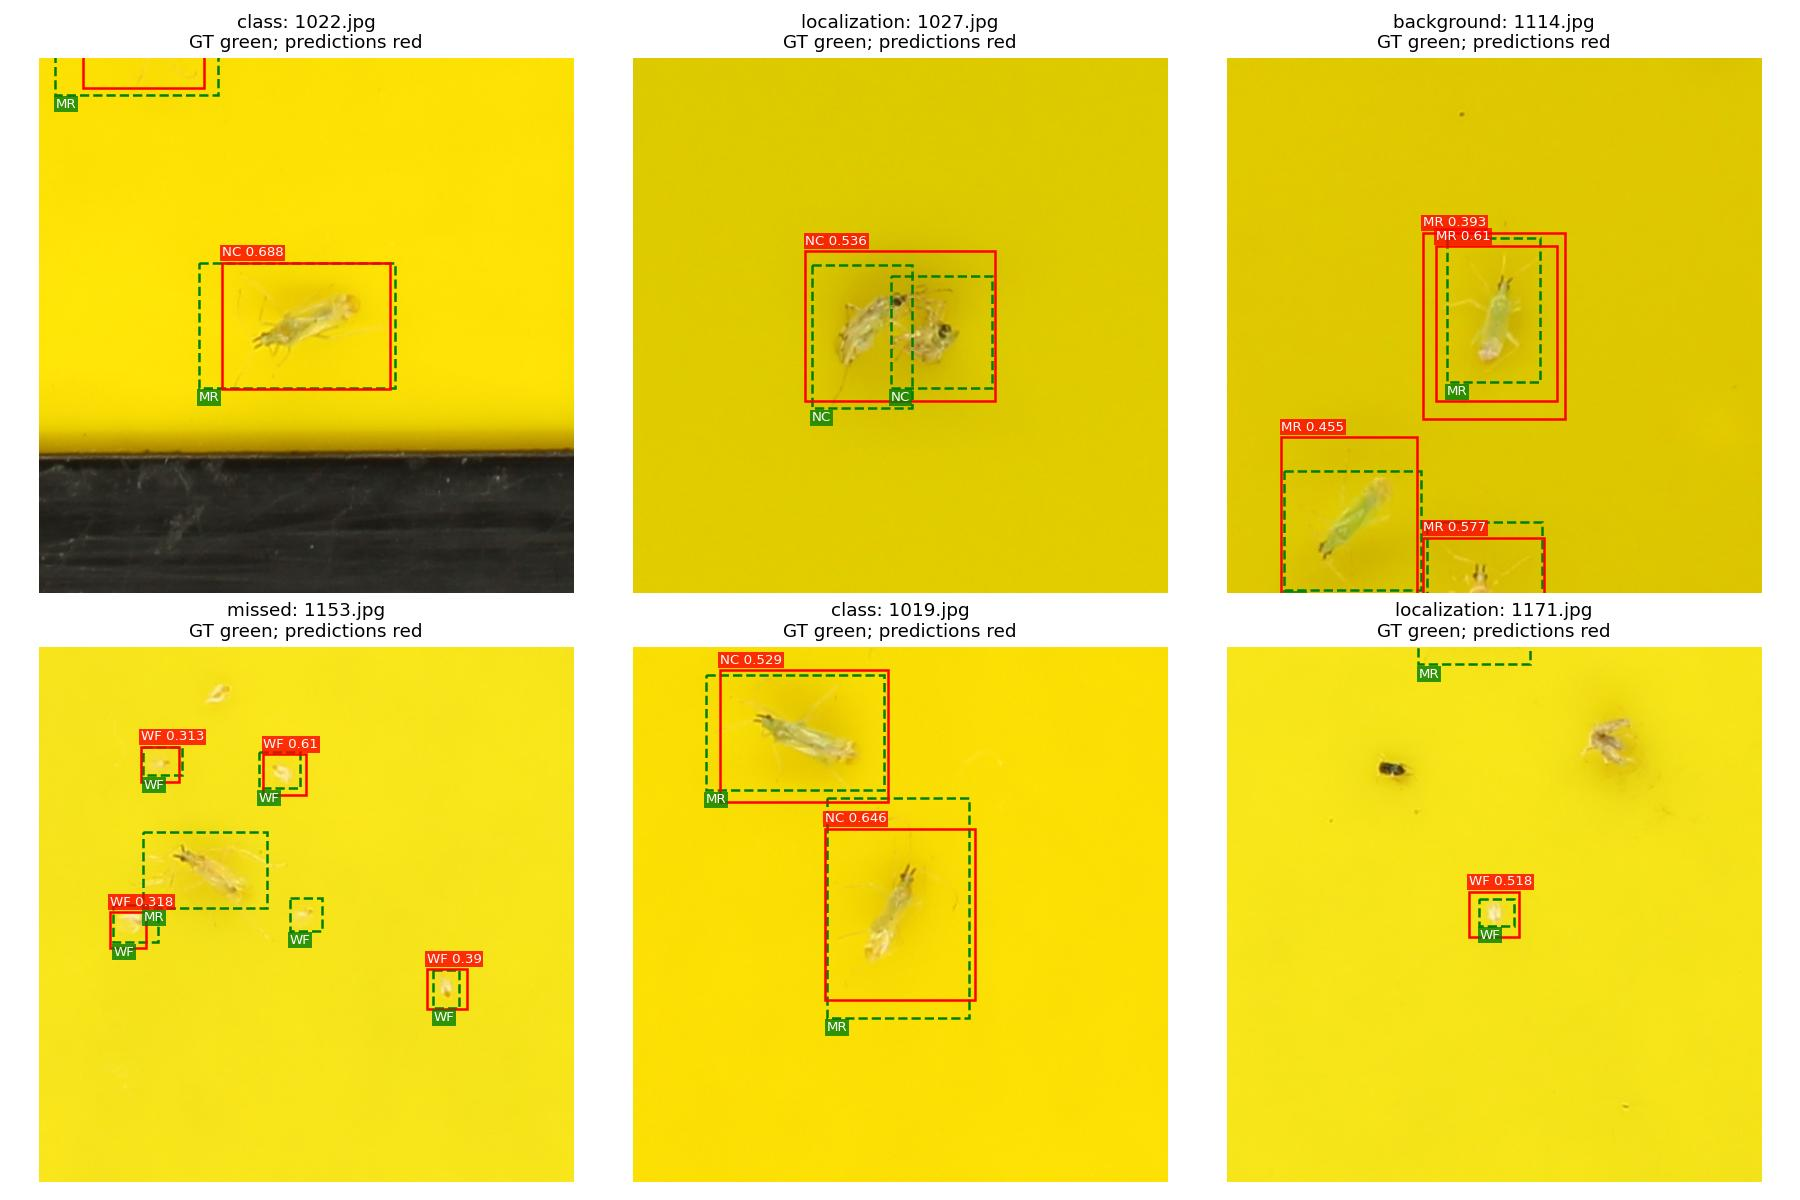

In [28]:
start = time.perf_counter()
val_preds = predict_records(best, records["val"], conf=CONF_ERRORS, rect=False, iou=0.7)
ERRORS = dict.fromkeys(ERROR_TYPES, 0)
ERRORS_BY_CLASS = {name: dict.fromkeys(ERROR_TYPES, 0) for name in CLASSES}
error_examples = {category: [] for category in ERROR_TYPES if category != "tp"}

for image_index, (pred, gt) in enumerate(zip(val_preds, records["val"], strict=False)):
    categories, missed = categorize_predictions(pred, gt)

    for i, category in enumerate(categories):
        ERRORS[category] += 1
        ERRORS_BY_CLASS[CLASSES[int(pred["labels"][i])]][category] += 1

        if category != "tp":
            error_examples[category].append((image_index, i, False))

    ERRORS["missed"] += len(missed)

    for j in missed:
        ERRORS_BY_CLASS[CLASSES[int(gt["labels"][j])]]["missed"] += 1
        error_examples["missed"].append((image_index, j, True))

RUN_TIMES["errors"] = time.perf_counter() - start
print("counts:", ERRORS)
print(
    "Доли среди предсказаний и необъяснённых пропусков:",
    {key: round(value / max(sum(ERRORS.values()), 1), 4) for key, value in ERRORS.items()},
)

for name, counts in ERRORS_BY_CLASS.items():
    print(name, counts)


# Визуализация не меняет полный подсчёт ERRORS выше.
# По возможности показываем разные категории и разные фотографии.
chosen, used_images = [], set()

for _level in range(6):
    for category, examples in error_examples.items():
        if len(chosen) >= 6:
            break

        example = next((e for e in examples if e[0] not in used_images), None)

        if example is not None:
            chosen.append((category, *example))
            used_images.add(example[0])

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax in axes.flat:
    ax.set_axis_off()

for ax, (category, image_index, box_index, is_gt) in zip(axes.flat, chosen, strict=False):
    gt, pred = records["val"][image_index], val_preds[image_index]
    target = gt["boxes"][box_index] if is_gt else pred["boxes"][box_index]
    window = box_window(target, gt["width"], gt["height"], min_side=500, max_side=1000)
    gt_indices = visible_boxes(gt["boxes"], window)
    pred_indices = visible_boxes(pred["boxes"], window)
    pred_indices = pred_indices[np.argsort(-pred["scores"][pred_indices], kind="stable")[:8]]

    if not is_gt:
        pred_indices = np.unique(np.r_[pred_indices, box_index])

    with Image.open(gt["image"]) as image:
        draw_crop(ax, image, window)
        draw_boxes(
            ax,
            None,
            gt["boxes"][gt_indices],
            gt["labels"][gt_indices],
            CLASSES,
            color="green",
            linestyle="--",
        )
        draw_boxes(
            ax,
            None,
            pred["boxes"][pred_indices],
            pred["labels"][pred_indices],
            CLASSES,
            scores=pred["scores"][pred_indices],
            color="red",
        )

    set_window(ax, window)
    ax.set_title(
        f"{category}: {gt['image'].name}\n"
        f"GT green; predictions red, shown {len(pred_indices)}/{len(pred['boxes'])}",
        fontsize=10,
    )

plt.tight_layout()
plt.show()

**Ответ:**

При conf = 0,25 на val получилось 925 правильных предсказаний, 8 ошибок класса, 117 ошибок локализации, 468 фоновых предсказаний и 198 необъясненных пропусков. Среди 791 ошибки без учета правильных детекций фоновые предсказания составляют около 59,2 процента, то есть это основная категория.

Большая часть фоновых предсказаний и ошибок локализации относится к Trialeurodes vaporariorum: 382 и 108 соответственно. Малый размер белокрылки затрудняет точную локализацию, а похожие светлые элементы ловушки могут давать лишние срабатывания. При этом категория background по нашему правилу включает и дубли уже найденных объектов.

На изображении 1114 видны несколько предсказаний вокруг одних и тех же насекомых, то есть часть фоновых ошибок связана с дублями. На 1022 и 1019 модель путает MR и NC, на 1027 один предсказанный бокс охватывает двух соседних насекомых. На 1153 видны объекты разметки, для которых нет подходящего предсказания. Эти примеры подтверждают наличие ошибок модели, но не позволяют объявить всю исходную разметку безошибочной.

Для уменьшения основной категории можно проверить ветку one2many с NMS и подобрать conf на val. Для мелких объектов также имеет смысл обучение на фрагментах исходных фотографий, чтобы сохранялось больше деталей. Перед изменением разметки спорные случаи нужно проверить вручную. На картинках показана только часть предсказаний в увеличенном фрагменте, а счетчики рассчитаны по всем предсказаниям. Примеры перерисованы по best.pt на CPU, численные итоги взяты из полного прогона на RTX 3060.


## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
# Меняем только imgsz, начальные веса и остальные параметры те же.
ABLATION_IMGSZ = 640 if FAST_MODE else 320
ablation_args = {**TRAIN_ARGS, "imgsz": ABLATION_IMGSZ}
model_ablation, RUN_TIMES["ablation"], ablation_dir = train_yolo(
    f"ablation_imgsz_{RUN_TAG}", **ablation_args
)
ablation_best = YOLO(ablation_dir / "weights" / "best.pt")
ablation_eval = val_metrics(ablation_best, "val", f"ablation_val_{RUN_TAG}", imgsz=ABLATION_IMGSZ)
ABLATION = dict(
    parameter="imgsz",
    split="val",
    variants=[
        dict(value=IMGSZ, **FINAL_BY_SPLIT["val"], train_time_sec=RUN_TIMES["train"]),
        dict(
            value=ABLATION_IMGSZ,
            **metric_summary(ablation_eval),
            train_time_sec=RUN_TIMES["ablation"],
        ),
    ],
)

for result in ABLATION["variants"]:
    print({key: value for key, value in result.items() if key != "per_class"})

del model_ablation, ablation_best

if torch.cuda.is_available():
    torch.cuda.empty_cache()

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
Overriding model.yaml nc=80 with nc=3

YOLO26n summary: 260 layers, 2,504,970 parameters, 2,504,970 gradients, 5.8 GFLOPs

Transferred 606/708 items from pretrained weights
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: checks passed 
optimizer: AdamW(lr=0.001, momentum=0.937) with parameter groups 114 weight(decay=0.0), 126 weight(decay=0.0005), 126 bias(decay=0.0)
Plotting labels to D:\Deep-Learning-homeworks\runs_hw2\ablation_imgsz_full\labels.jpg... 
Image sizes 320 train, 320 val
Using 0 dataloader workers
Logging results to D:\Deep-Learning-homeworks\runs_hw2\ablation_imgsz_full
Starting training for 60 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/60      1.09G      4.007      4.726   0.009697        133        320
      

**Ответ:**

В абляции сравнивались разрешения 640 и 320 при одинаковом наборе train, seed и остальных заданных гиперпараметрах. На val размер 640 дал mAP50 = 0,7486 и mAP50-95 = 0,3256, размер 320 - 0,4902 и 0,1794. Повышение разрешения дало около 25,84 процентного пункта по mAP50 и 14,62 по mAP50-95.

Наибольший выигрыш по mAP50 получен для Trialeurodes vaporariorum: 0,6725 против 0,3556. Это согласуется с размерами объектов и прошлыми рассуждениями: при 320 медианный размер белокрылки около 2,9 пикселя, при 640 - около 5,8. В первом случае модель получает значительно меньше деталей для определения положения и границ насекомого.

Основной прогон занял около 1267 секунд, абляция - 1200 секунд. При этом основной прогон остановился на 55-й эпохе, а абляция выполнила все 60, поэтому получилось не совсем чистое сравнение. В обоих замерах также учитывались подготовка данных и валидация. Для данного бюджета разрешение 640 оправдано, т.к. качество выросло существенно при небольшом различии общего времени.


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:**

Дообучение YOLO26n позволило получить test mAP50 = 0,7466 при нулевом результате COCO-модели и цветовой эвристики. При этом mAP50-95 составил 0,3237, то есть точная локализация остается заметно сложнее обнаружения при IoU 0,5. Увеличение разрешения с 320 до 640 повысило val mAP50 с 0,4902 до 0,7486, особенно сильно улучшив детекцию белокрылки. Основная категория ошибок - лишние предсказания и дубли, которых на val оказалось 468. RT-DETR с выбранными настройками получила val mAP50 = 0,0379 и потребовала больше времени, поэтому в этом эксперименте предпочтительнее YOLO26n. Наиболее сильное падение качества вызвал гауссов шум: val mAP50 уменьшился с 0,7486 до 0,3048, а переход на FP16 ускорения не дал. Выводы ограничены одним seed, val из 42 изображений и возможными неточностями разметки. Для RT-DETR также было предупреждение о недетерминированной CUDA-операции.

В дальнейшем на мой взгляд стоило бы сделать следующее:
1) Увеличить размер входа (видно по абляции, что дало прирост)
2) Увеличить количество и разнообразие реальных данных
3) Можно поменять подход к инференсу и обучению: нарезать изображение на тайлы и инференсить модель по ним, затем уже думать как обрабатывать границы. Например, можно было бы использовать перекрывающиеся тайлы и удалять дубли после объединения предсказаний. Причём в таком случае можно будет попробовать уменьшить размер входа и сравнить скорость инференса на одном изображении. Я предполагаю, что соотношение качество / скорость может оказаться даже лучше, чем при текущем подходе
4) Добавить своих аугментаций, например делать copy-paste насекомых вместе с разметкой. В пользу этого говорит также однородность фона (частично).
5) Изучить FP и в качестве аугментаций попробовать имитировать именно их

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/hw2/metrics.json` (общий формат ДЗ2), `artifacts/hw2/results.csv` и `artifacts/hw2/best.pt`. Выполняется и в FAST_MODE для проверки формата. При окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())

    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())

    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}

    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]

    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, Path):
        return value.as_posix()

    return value


artifact_dir = Path("artifacts") / "hw2"
artifact_dir.mkdir(parents=True, exist_ok=True)
metrics = dict(
    track="cv",
    model=WEIGHTS,
    revision=f"ultralytics=={MODEL_INFO['ultralytics']}; sha256={MODEL_INFO['sha256']}",
    dataset=DATASET_NAME,
    dataset_url=DATASET_URL,
    dataset_license=DATASET_LICENSE,
    classes=CLASSES,
    n_train=len(train_recs),
    n_val=len(records["val"]),
    n_test=len(records["test"]) if "test" in records else None,
    params_total=int(sum(blocks.values())),
    baseline=BASELINE,
    final=FINAL,
    ablation=ABLATION,
    errors=ERRORS,
    device=DEVICE_NAME,
    train_time_sec=RUN_TIMES["train"],
    fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS,
    run_times=RUN_TIMES,
    final_by_split=FINAL_BY_SPLIT,
    errors_by_class=ERRORS_BY_CLASS,
)
(artifact_dir / "metrics.json").write_text(
    json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8"
)
shutil.copy(run_dir / "results.csv", artifact_dir / "results.csv")
shutil.copy(run_dir / "weights" / "best.pt", artifact_dir / "best.pt")
print("Сохранено:", [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'BoxPR_curve.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'metrics.json', 'results.csv', 'rtdetr_results.csv', 'training_curves.png']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if "6.1" in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:**

Бонус 6.1 не выполнялся. Для дополнительных баллов выбраны задачи 6.2, 6.3, 6.4 и 6.5.


## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if "6.2" in BONUS_TASKS:
    transformer = RTDETR("rtdetr-l.pt")
    rtdetr_weights = (
        Path("rtdetr-l.pt") if Path("rtdetr-l.pt").exists() else Path(transformer.ckpt_path)
    )
    # Тот же train/val, число эпох, разрешение и seed; меньший batch и lr для RT-DETR.
    RTDETR_ARGS = {**TRAIN_ARGS, "batch": 2 if FAST_MODE else 4, "lr0": 0.0001}
    start = time.perf_counter()
    transformer.train(
        data=str(DATA_YAML),
        device=DEVICE,
        workers=WORKERS,
        project=str(RUNS.resolve()),
        name=f"rtdetr_{RUN_TAG}",
        exist_ok=True,
        verbose=False,
        **RTDETR_ARGS,
    )
    RUN_TIMES["rtdetr_train"] = time.perf_counter() - start
    rtdetr_dir = Path(transformer.trainer.save_dir)
    rtdetr_best = RTDETR(rtdetr_dir / "weights" / "best.pt")
    rtdetr_params = sum(p.numel() for p in rtdetr_best.model.parameters())
    rtdetr_eval = val_metrics(
        rtdetr_best, "val", f"rtdetr_val_{RUN_TAG}", batch=RTDETR_ARGS["batch"]
    )

    with Image.open(records["val"][0]["image"]) as image:
        benchmark_image = np.asarray(image.convert("RGB").resize((IMGSZ, IMGSZ)))[:, :, ::-1].copy()

    yolo_latency = latency_ms(best, benchmark_image, half=False)
    rtdetr_latency = latency_ms(rtdetr_best, benchmark_image, half=False)
    BONUS_RESULTS["6.2"] = dict(
        yolo=dict(
            **FINAL_BY_SPLIT["val"],
            params=FINETUNED_PARAMS,
            train_time_sec=RUN_TIMES["train"],
            latency_ms=yolo_latency,
        ),
        rtdetr=dict(
            **metric_summary(rtdetr_eval),
            params=rtdetr_params,
            train_time_sec=RUN_TIMES["rtdetr_train"],
            latency_ms=rtdetr_latency,
        ),
        train_args=RTDETR_ARGS,
        weights_sha256=file_sha256(rtdetr_weights),
        split="val",
    )
    for name in ("yolo", "rtdetr"):
        result = BONUS_RESULTS["6.2"][name]
        print_metric_summary(name, result)
        timing = result["latency_ms"]
        print(f"params: {result['params']:,}; train: {result['train_time_sec']:.1f} s")
        print(f"predict mean: {timing['mean']:.2f} ms; std: {timing['std']:.2f} ms")
        print()
    del transformer, rtdetr_best

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
Overriding model.yaml nc=80 with nc=3
WARNING no model scale passed. Assuming scale='l'.

rt-detr-l summary: 465 layers, 32,812,241 parameters, 32,812,241 gradients, 109.9 GFLOPs

Transferred 926/941 items from pretrained weights
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: checks passed 
optimizer: AdamW(lr=0.0001, momentum=0.937) with parameter groups 143 weight(decay=0.0), 206 weight(decay=0.0005), 226 bias(decay=0.0)
Plotting labels to D:\Deep-Learning-homeworks\runs_hw2\rtdetr_full\labels.jpg... 
Image sizes 640 train, 640 val
Using 0 dataloader workers
Logging results to D:\Deep-Learning-homeworks\runs_hw2\rtdetr_full
Starting training for 60 epochs...

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       1/60       3.3G      2.098      3.4

D:\Deep-Learning-homeworks\.venv\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
Предупреждение повторялось в исходном логе 60 раз.


       1/60      4.86G      2.968     0.5709     0.8567         12        640
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         42       1225          0          0          0          0

       2/60      5.05G      2.597    0.04225     0.5148        264        640


       2/60      5.77G      2.403     0.1308      0.709         23        640
                   all         42       1225   0.000248    0.00791   1.66e-05   4.05e-06

       3/60      5.77G      2.339    0.05782     0.5792         57        640


       3/60      5.77G      2.382     0.1059     0.6007         28        640
                   all         42       1225   7.98e-05    0.00395   1.76e-06   2.92e-07

       4/60      5.77G      2.164     0.1499     0.4767        159        640


       4/60      5.77G      2.234     0.1455     0.4846         23        640
                   all         42       1225   0.000159    0.00791   5.48e-06   5.48e-07

       5/60      5.77G      1.931     0.2908     0.3937         43        640


... (52 outputs left out)

      57/60      5.66G      1.137     0.5415     0.1139         45        640
                   all         42       1225     0.0365       0.43     0.0413    0.00768

      58/60      5.66G      1.385     0.2557     0.1084        246        640


      58/60      5.66G      1.145     0.5277     0.1092         14        640
                   all         42       1225     0.0421      0.411     0.0411    0.00763

      59/60      5.66G      1.176     0.4259    0.09074        192        640


      59/60      5.66G      1.142     0.5218     0.1107         60        640
                   all         42       1225      0.043      0.412     0.0399    0.00717

      60/60      5.66G      1.115     0.5307    0.09589         87        640


      60/60      5.66G      1.142     0.5289       0.11        174        640
                   all         42       1225      0.036      0.425      0.042    0.00759

60 epochs completed in 0.904 hours.
Optimizer stripped from D:\Deep-Learning-homeworks\runs_hw2\rtdetr_full\weights\last.pt, 66.2MB
Optimizer stripped from D:\Deep-Learning-homeworks\runs_hw2\rtdetr_full\weights\best.pt, 66.2MB

Validating D:\Deep-Learning-homeworks\runs_hw2\rtdetr_full\weights\best.pt...
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
rt-detr-l summary: 310 layers, 31,989,905 parameters, 0 gradients, 105.3 GFLOPs
                   all         42       1225     0.0366      0.432     0.0377    0.00711
Speed: 0.6ms preprocess, 27.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to D:\Deep-Learning-homeworks\runs_hw2\rtdetr_full
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
rt-detr-l summar

**Ответ:**

На val YOLO26n получила mAP50 = 0,7486 и mAP50-95 = 0,3256, RT-DETR - 0,0379 и 0,0071. Precision у RT-DETR составила всего 0,0367 при recall 0,4337. То есть с выбранными настройками трансформерный детектор дает много ложных срабатываний и значительно уступает YOLO.

До слияния слоев дообученная YOLO содержит около 2,50 млн параметров, RT-DETR - 32,81 млн. Обучение заняло около 21,1 минуты для YOLO и 55,0 минуты для RT-DETR. Средняя задержка полного predict на RTX 3060 при размере 640 составила 18,90 и 40,50 мс соответственно, то есть RT-DETR была примерно в 2,14 раза медленнее.

Для RT-DETR использовались batch 4 и lr 0,0001, для YOLO - batch 16 и lr 0,001. Фактически выполнены 60 и 55 эпох. Поэтому вывод относится к конкретным настройкам и этому небольшому датасету. При обучении RT-DETR PyTorch также предупреждал, что grid_sampler_2d_backward_cuda не имеет детерминированной реализации, поэтому фиксированный seed не гарантирует побитового повторения результата.

Дополнительно в warmup для bias остался параметр warmup_bias_lr = 0,1. По results.csv после первой эпохи lr этой группы составлял около 0,0674 при базовом lr0 = 0,0001. Поэтому влияние warmup стоит проверить отдельно, прежде чем связывать низкое качество только с архитектурой или отсутствием заморозки слоев. В этом эксперименте такое сравнение не проводилось.

Для данной задачи я бы выбрал YOLO26n. RT-DETR имеет смысл рассматривать после отдельной настройки обучения, если на целевых данных она дает выигрыш по качеству, который оправдывает больший размер модели и вычислительную стоимость.


## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [33]:
if "6.3" in BONUS_TASKS:
    corruption_root = DATA_ROOT / "hw2_sticky_corruptions"
    CORRUPTIONS = dict(dark=dict(brightness=0.35), noise=dict(sigma=25), jpeg=dict(quality=10))
    corruption_results = dict(clean=FINAL_BY_SPLIT["val"])
    start = time.perf_counter()

    for kind, settings in CORRUPTIONS.items():
        image_dir = corruption_root / kind / "images" / "val"
        label_dir = corruption_root / kind / "labels" / "val"
        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)
        rng = np.random.default_rng(SEED)

        for r in records["val"]:
            with Image.open(r["image"]) as original:
                image = original.convert("RGB")

                if kind == "dark":
                    image = ImageEnhance.Brightness(image).enhance(settings["brightness"])
                elif kind == "noise":
                    pixels = np.asarray(image, dtype=np.float32)
                    pixels += (
                        rng.standard_normal(pixels.shape, dtype=np.float32) * settings["sigma"]
                    )
                    image = Image.fromarray(np.clip(pixels, 0, 255).astype(np.uint8))

                # Новые файлы: сюда нельзя ставить hard link на исходники.
                image.save(image_dir / r["image"].name, quality=settings.get("quality", 95))

            (label_dir / f"{r['image'].stem}.txt").write_text(
                to_yolo(r["boxes"], r["labels"], r["width"], r["height"]), encoding="utf-8"
            )

        yaml_path = corruption_root / kind / "data.yaml"
        yaml_path.write_text(
            f"path: {yaml_path.parent.resolve().as_posix()}\n"
            + "train: images/val\nval: images/val\nnames:\n"
            + "".join(f"  {i}: {name}\n" for i, name in enumerate(CLASSES)),
            encoding="utf-8",
        )
        result = val_metrics(best, "val", f"corruption_{kind}_{RUN_TAG}", data=str(yaml_path))
        corruption_results[kind] = metric_summary(result)

    RUN_TIMES["corruptions"] = time.perf_counter() - start
    BONUS_RESULTS["6.3"] = dict(settings=CORRUPTIONS, metrics=corruption_results, split="val")

    for kind, values in corruption_results.items():
        print_metric_summary(kind, values)

Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         42       1225      0.655      0.596      0.631      0.254
Speed: 1.2ms preprocess, 10.0ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to D:\Deep-Learning-homeworks\runs_hw2\corruption_dark_full
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         42       1225      0.632      0.232      0.305      0.096
Speed: 1.3ms preprocess, 15.3ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to D:\Deep-Learning-homeworks\runs_hw2\corruption_noise_full
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
                 Class     Images  Instan

**Ответ:**

На чистой val mAP50 = 0,7486, после затемнения - 0,6309, после добавления шума - 0,3048, после JPEG-сжатия - 0,5679. Соответствующие mAP50-95 равны 0,3256, 0,2539, 0,0960 и 0,2057. То есть сильнее всего повлиял гауссов шум: снижение mAP50 составило около 44,38 процентного пункта.

При добавлении шума mAP50 для MR уменьшился с 0,7812 до 0,2805, для NC - с 0,7921 до 0,3133, для WF - с 0,6725 до 0,3205. Наибольшая потеря по абсолютной величине получилась у MR, хотя WF является самым мелким классом. Следовательно, влияние искажений определяется не только размером объекта, но и тем, какие признаки использует модель.

Проверялись яркость 0,35 от исходной, шум со стандартным отклонением 25 и JPEG quality 10. Для повышения устойчивости можно добавлять шум и случайное JPEG-сжатие в train, а диапазон изменений яркости расширить под ожидаемые условия съемки. Эти изменения нужно проверить отдельным обучением, т.к. текущий эксперимент измеряет чувствительность уже обученной модели.


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if "6.4" in BONUS_TASKS:
    # Разрешённый в условии альтернативный способ ускорения: FP16 на той же CUDA GPU.
    assert torch.cuda.is_available(), "Для сравнения FP32/FP16 запусти notebook на CUDA GPU"

    with Image.open(records["val"][0]["image"]) as image:
        speed_image = np.asarray(image.convert("RGB").resize((IMGSZ, IMGSZ)))[:, :, ::-1].copy()

    precision_results = {}

    for precision, half in [("fp32", False), ("fp16", True)]:
        speed_model = YOLO(run_dir / "weights" / "best.pt")
        timing = latency_ms(speed_model, speed_image, repeats=30, half=half)
        result = val_metrics(speed_model, "val", f"{precision}_{RUN_TAG}", half=half)
        precision_results[precision] = dict(latency_ms=timing, **metric_summary(result))
        del speed_model

    acceleration = (
        precision_results["fp32"]["latency_ms"]["mean"]
        / precision_results["fp16"]["latency_ms"]["mean"]
    )
    map_delta = precision_results["fp16"]["map50"] - precision_results["fp32"]["map50"]
    BONUS_RESULTS["6.4"] = dict(
        method="CUDA FP16",
        device=DEVICE_NAME,
        split="val",
        imgsz=IMGSZ,
        batch=1,
        speedup=acceleration,
        map50_delta=map_delta,
        results=precision_results,
    )
    for name, result in precision_results.items():
        print_metric_summary(name, result)
        timing = result["latency_ms"]
        print(f"predict mean: {timing['mean']:.2f} ms; std: {timing['std']:.2f} ms")
        print()
    print(f"Отношение времени FP32 / FP16: {acceleration:.3f}; delta mAP50: {map_delta:+.6f}")
    print("mAP50 не снизился больше чем на 0.001:", map_delta >= -0.001)
    torch.cuda.empty_cache()

Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         42       1225      0.714      0.707      0.749      0.326
Speed: 1.0ms preprocess, 8.6ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to D:\Deep-Learning-homeworks\runs_hw2\fp32_full
Ultralytics 8.4.40  Python-3.14.4 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         42       1225      0.711      0.707      0.747      0.326
Speed: 0.8ms preprocess, 9.7ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to D:\Deep-Learning-homeworks\runs_hw2\fp16_full
fp32
class             P         R     mAP50    mAP50-95
all          0.7142    0.7068    0.7486      0.3256
MR           0.7928    0.6202    0.7812      0.3419
N

**Ответ:**

При batch 1 и размере 640 полный predict на RTX 3060 в среднем занял 20,00 мс для FP32 и 22,41 мс для FP16. Отношение времён составляет 0,892, то есть в данном замере FP16 ускорения не дал и оказался примерно на 12,0 процента медленнее.

Стандартные отклонения составили 2,76 и 3,48 мс. Разница средних сопоставима с разбросом отдельных запусков, поэтому этот результат не стоит переносить на другие размеры модели и batch. FP16 может ускорять матричные вычисления и уменьшать передачу данных, но при маленькой модели на общее время также влияют preprocessing, postprocessing и накладные расходы вызова predict.

mAP50 на val изменился с 0,748605 до 0,747378, то есть снизился примерно на 0,001227, или 0,123 процентного пункта. Проверка допуска 0,001 из кода не прошла, хотя падение небольшое; mAP50-95 при этом изменился с 0,325579 до 0,326086. Для текущих условий я бы оставил FP32. Эксперимент не подтвердил ускорение и не дал основания утверждать, что качество совсем не изменилось.


## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

end2end   iou    conf      P       R     mAP50
True     0.3   0.001  0.1142  0.9167  0.7463
True     0.3   0.100  0.4005  0.8547  0.7228
True     0.3   0.250  0.6098  0.7551  0.6617
True     0.3   0.500  0.8457  0.3535  0.3749
True     0.7   0.001  0.1142  0.9167  0.7463
True     0.7   0.100  0.4005  0.8547  0.7228
True     0.7   0.250  0.6098  0.7551  0.6617
True     0.7   0.500  0.8457  0.3535  0.3749
False    0.3   0.001  0.1269  0.8522  0.8074
False    0.3   0.100  0.5738  0.8286  0.7898
False    0.3   0.250  0.6878  0.7894  0.7584
False    0.3   0.500  0.8326  0.6498  0.6416
False    0.7   0.001  0.1062  0.8824  0.8162
False    0.7   0.100  0.4466  0.8506  0.7983
False    0.7   0.250  0.6012  0.8024  0.7661
False    0.7   0.500  0.8276  0.6506  0.6417


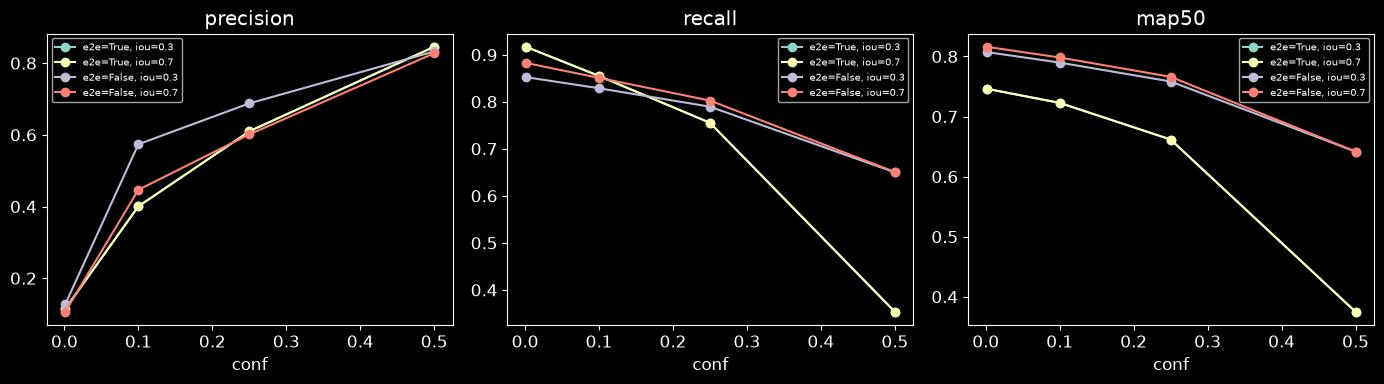

In [35]:
def precision_recall_at_conf(preds, gts, conf, iou_threshold=0.5):
    tp = np.zeros(len(CLASSES), dtype=int)
    fp = np.zeros(len(CLASSES), dtype=int)
    total = np.zeros(len(CLASSES), dtype=int)

    for pred, gt in zip(preds, gts, strict=False):
        total += np.bincount(gt["labels"], minlength=len(CLASSES))
        ious = box_iou_np(pred["boxes"], gt["boxes"])
        found = np.zeros(len(gt["labels"]), dtype=bool)

        for i in np.argsort(-pred["scores"], kind="stable"):
            if pred["scores"][i] < conf:
                continue

            label = int(pred["labels"][i])
            candidates = np.flatnonzero(
                (gt["labels"] == label) & ~found & (ious[i] >= iou_threshold)
            )

            if len(candidates):
                j = candidates[np.argmax(ious[i, candidates])]
                found[j] = True
                tp[label] += 1
            else:
                fp[label] += 1

    fn = total - tp
    per_class = {
        name: dict(
            precision=float(tp[c] / max(tp[c] + fp[c], 1)),
            recall=float(tp[c] / max(total[c], 1)),
            tp=int(tp[c]),
            fp=int(fp[c]),
            fn=int(fn[c]),
        )
        for c, name in enumerate(CLASSES)
    }

    return dict(
        precision=float(tp.sum() / max((tp + fp).sum(), 1)),
        recall=float(tp.sum() / max(total.sum(), 1)),
        per_class=per_class,
    )


if "6.5" in BONUS_TASKS:
    start = time.perf_counter()
    conf_grid = [0.001, 0.01, 0.1, 0.25] if FAST_MODE else [0.001, 0.1, 0.25, 0.5]
    iou_grid = [0.3, 0.7]
    threshold_results = []

    for end2end in (True, False):
        # Свежая модель для каждого режима: fuse может удалить one2many-ветку.
        for iou in iou_grid:
            threshold_model = YOLO(run_dir / "weights" / "best.pt")
            predictions = predict_records(
                threshold_model,
                records["val"],
                batch=1,
                conf=min(conf_grid),
                rect=False,
                iou=iou,
                end2end=end2end,
            )

            for conf in conf_grid:
                filtered = [
                    {key: value[pred["scores"] >= conf] for key, value in pred.items()}
                    for pred in predictions
                ]
                map50, aps = evaluate_map50(filtered, records["val"], len(CLASSES))
                values = precision_recall_at_conf(filtered, records["val"], conf)
                threshold_results.append(
                    dict(
                        end2end=end2end,
                        iou=iou,
                        conf=conf,
                        map50=map50,
                        ap50_per_class=dict(zip(CLASSES, aps, strict=False)),
                        **values,
                    )
                )

            del threshold_model

    RUN_TIMES["thresholds"] = time.perf_counter() - start
    BONUS_RESULTS["6.5"] = dict(
        split="val",
        metrics=threshold_results,
        pr_definition="micro P/R at fixed conf, same class, IoU >= 0.5",
    )
    print("end2end   iou    conf      P       R     mAP50")

    for row in threshold_results:
        print(
            f"{row['end2end']!s:7}  {row['iou']:.1f}  {row['conf']:6.3f}  "
            f"{row['precision']:.4f}  {row['recall']:.4f}  {row['map50']:.4f}"
        )

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    for end2end in (True, False):
        for iou in iou_grid:
            rows = [
                row for row in threshold_results if row["end2end"] == end2end and row["iou"] == iou
            ]

            for ax, metric in zip(axes, ("precision", "recall", "map50"), strict=False):
                ax.plot(
                    [row["conf"] for row in rows],
                    [row[metric] for row in rows],
                    "o-",
                    label=f"e2e={end2end}, iou={iou}",
                )
                ax.set_title(metric)
                ax.set_xlabel("conf")
                ax.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

**Ответ:**

В режиме end-to-end значения метрик для iou 0,3 и 0,7 совпали на всей сетке conf. Это ожидаемо, т.к. в данной ветке NMS не применяется. При повышении conf с 0,001 до 0,5 precision выросла с 0,1142 до 0,8457, а recall уменьшился с 0,9167 до 0,3535.

В этом эксперименте mAP50 заметно зависит от conf: для end-to-end он уменьшился с 0,7463 до 0,3749. AP учитывает ранжирование по score, но высокий порог удаляет часть правильных предсказаний и ограничивает достижимый recall. Поэтому слабую зависимость от conf можно ожидать только в диапазоне достаточно низких порогов, а не на всей сетке.

В ветке one2many порог NMS влияет на результат. При conf = 0,25 изменение iou с 0,3 до 0,7 уменьшило precision с 0,6878 до 0,6012 и повысило recall с 0,7894 до 0,8024. Менее строгое подавление сохраняет больше пересекающихся боксов, включая дубли. При низком conf эта ветка также дала более высокий собственный mAP50: до 0,8162 против 0,7463 у end-to-end.

Для рабочей точки на этой val я бы выбрал one2many, conf = 0,25 и iou = 0,3: precision = 0,6878, recall = 0,7894. Это компромисс между пропусками и лишними срабатываниями; при большей цене пропуска можно проверить conf = 0,1, где recall = 0,8286 при precision = 0,5738. Здесь P и R считаются по всем объектам при фиксированном пороге, поэтому они отличаются от усредненных по классам значений Ultralytics, выбранных по максимуму F1.


In [36]:
# Сохраняем бонусы после их выполнения, не перезаписывая artifacts первого ДЗ.
metrics["bonuses"] = BONUS_RESULTS
metrics["bonus_tasks"] = sorted(BONUS_TASKS)
metrics["run_times"] = RUN_TIMES
metrics["split_images"] = {
    split: [r["image"].name for r in recs] for split, recs in records.items()
}
metrics["dataset_images_sha256"] = dict(
    zip([r["image"].name for r in all_records], hashes, strict=False)
)
(artifact_dir / "metrics.json").write_text(
    json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8"
)

for filename in ("BoxPR_curve.png", "confusion_matrix.png", "confusion_matrix_normalized.png"):
    source = validation_dir / filename

    if source.exists():
        shutil.copy2(source, artifact_dir / filename)

if (run_dir / "results.png").exists():
    shutil.copy2(run_dir / "results.png", artifact_dir / "training_curves.png")

if "6.2" in BONUS_RESULTS:
    shutil.copy2(rtdetr_dir / "results.csv", artifact_dir / "rtdetr_results.csv")

print("Результаты ДЗ2:", artifact_dir.resolve())

Результаты ДЗ2: D:\Deep-Learning-homeworks\artifacts\hw2
